# Deep Metagenomics of the Human Gut Microbiome in Inflammatory Bowel Disease
## Compositional Ecology, Explainable Machine Learning, and Longitudinal Analysis

---

**Original notebook adapted from**: Qasim Hu, *Human Gut Microbiome Atlas* (Kaggle)  
**Dataset**: HMP2 Inflammatory Bowel Disease Multi-omics Database (IBDMDB)  
**Profiling**: MetaPhlAn 3.0 taxonomic profiles at species-level resolution  
**Cohort structure**: 116 participants sampled repeatedly over time  
**Raw atlas note**: the published CSV contains duplicated sample rows; the analysis below deduplicates by sample identifier before use  
**Groups**: Healthy controls, Crohn's Disease, Ulcerative Colitis  
**Temporal scope**: approximately 57 weeks of serial sampling

---

## Abstract

This notebook analyzes longitudinal HMP2 IBDMDB metagenomic profiles while accounting for three properties that materially affect inference: repeated sampling of participants, compositional relative-abundance data, and duplicated rows in the published atlas. The workflow deduplicates sample identifiers, computes ecological diversity from the unfiltered species table, performs participant-level statistical comparisons, applies centered log-ratio (CLR) transformation after prevalence filtering and renormalization, evaluates ordination with PERMANOVA, and assesses machine-learning performance with participant-grouped cross-validation. Interpretive statements are generated from computed results or clearly labeled as exploratory.

## Research Objectives

1. Characterize the taxonomic landscape across clinical groups
2. Quantify alpha diversity without removing rare taxa before calculation
3. Map beta diversity in Aitchison space and formally test group separation
4. Identify differentially abundant taxa using participant-level inference and FDR correction
5. Evaluate predictive performance without longitudinal train/test leakage
6. Explore longitudinal trajectories without treating repeated samples as independent participants
7. Reconstruct a CLR-based co-occurrence network with FDR-controlled edges
8. Integrate fecal calprotectin with participant-level microbial summaries

---


## Correction Log

This revised notebook implements the issues documented in the accompanying review.

| Area | Change made |
|---|---|
| Provenance and cohort description | Added original-notebook attribution; replaced duplicate-inflated cohort language with 116 longitudinal participants and deduplicated sample counts computed at runtime. |
| Duplicate rows | Deduplicates by sample identifier after prioritizing non-missing fecal-calprotectin records; asserts a unique index. |
| Pseudoreplication | Differential abundance, alpha-diversity tests, dysbiosis correlations, and clinical correlations now use one mean per participant. |
| Multiple testing | Retains Benjamini–Hochberg FDR correction and removes network fallbacks that silently used uncorrected p-values or strongest edges. |
| Alpha diversity | Computes richness, Shannon, Simpson, and Pielou on the unfiltered species table; empty samples return `NaN` diversity rather than Simpson = 1. |
| Filtering and closure | Renormalizes the prevalence-filtered table to 100% and excludes zero-mass rows from CLR-based analyses. |
| CLR zero handling | Replaces one global pseudocount with row-wise multiplicative zero replacement. |
| Ordination inference | Adds participant-level PERMANOVA instead of treating visual separation as a statistical result. |
| Dysbiosis score | Removes *Bacteroides fragilis* from the predefined symbiont list. |
| Co-occurrence network | Uses `clr_data`, fixed FDR/effect thresholds, and no noise-generating fallback cascade. |
| Machine learning | Adds participant-grouped cross-validation, reports the majority-class baseline, and explicitly flags overfitting. |
| Hardcoded conclusions | Replaces unsupported result-like print statements with computed results or clearly descriptive language. |
| *F. prausnitzii* claim | Removes the unsupported “protective/depleted” conclusion and labels its figure exploratory. |

### Additional issues addressed or flagged

- Group composition bars now use participant-weighted means so heavily sampled participants do not dominate descriptive averages.
- “Log2 fold change” is clarified as a difference in mean CLR values expressed in log2 units.
- Clinical heatmaps and fecal-calprotectin scatterplots are participant-level.
- The genus-to-phylum assignment is flagged as a heuristic that should not be used for publication without an authoritative taxonomy mapping.
- Participant averaging is appropriate for simple between-group comparisons but loses longitudinal information; mixed-effects models are recommended for visit-level questions.


## Section 1. Environment Configuration and Dependencies

The analytical framework integrates compositional statistics, machine learning, network science, and interactive visualization. All statistical tests employ non-parametric methods appropriate for the non-normal distributions characteristic of microbiome data. Compositional data transformations follow the foundational principles established by Aitchison (1986). Interactive three-dimensional visualizations are rendered through Plotly with the iframe renderer for compatibility with cloud notebook environments including Kaggle.

In [11]:
# ---------------------------------------------------------------------------
# Core data manipulation and numerical computing
# ---------------------------------------------------------------------------
import pandas as pd
import numpy as np
import warnings
import os
import glob
warnings.filterwarnings('ignore')

# ---------------------------------------------------------------------------
# Statistical analysis
# ---------------------------------------------------------------------------
from scipy.stats import (mannwhitneyu, kruskal, spearmanr, entropy,
                         pearsonr, sem)
from scipy.spatial.distance import pdist, squareform
from statsmodels.stats.multitest import multipletests

# ---------------------------------------------------------------------------
# Machine learning and explainable AI
# ---------------------------------------------------------------------------
import sklearn
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold,
                                      cross_validate, cross_val_predict,
                                      train_test_split, GridSearchCV)
from sklearn.metrics import (roc_curve, auc, classification_report,
                              confusion_matrix, accuracy_score,
                              precision_score, recall_score, f1_score)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
import shap

# ---------------------------------------------------------------------------
# Visualization
# ---------------------------------------------------------------------------
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import plotly.figure_factory as ff

# ---------------------------------------------------------------------------
# Network analysis
# ---------------------------------------------------------------------------
import networkx as nx

# ---------------------------------------------------------------------------
# Global configuration
# ---------------------------------------------------------------------------
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
pio.renderers.default = 'iframe'

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Professional color palettes
PALETTE_DIAGNOSIS = {
    'Healthy': '#1B9E77',
    'Crohns Disease': '#D95F02',
    'Ulcerative Colitis': '#7570B3'
}
PALETTE_DIAGNOSIS_LIST = ['#1B9E77', '#D95F02', '#7570B3']
PALETTE_BINARY = {'Healthy': '#1B9E77', 'Crohns Disease': '#D95F02'}
PALETTE_CONTINUOUS = 'Viridis'
PALETTE_DIVERGING = 'RdBu_r'

print("Environment configured successfully.")
print(f"  pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"  Plotly renderer: {pio.renderers.default}")
print(f"  Random seed: {SEED}")


Environment configured successfully.
  pandas 2.2.2 | numpy 2.1.1 | scikit-learn 1.5.2
  Plotly renderer: iframe
  Random seed: 42


## Section 2. Data Ingestion and Quality Control

The curated atlas was generated by stitching individual MetaPhlAn 3.0 taxonomic profiles from the HMP2 IBDMDB repository. Each row represents a stool-sample profile, but the published CSV contains repeated sample identifiers and many exact duplicate rows. Because this is a longitudinal cohort, repeated samples from one participant are not independent observations.

Quality control therefore proceeds in this order:

1. load the atlas and retain the non-missing fecal-calprotectin record when a sample identifier is repeated;
2. verify that sample identifiers are unique;
3. separate metadata and bacterial abundance columns;
4. verify the compositional total;
5. preserve the unfiltered abundance table for alpha-diversity calculations;
6. prevalence-filter and renormalize a separate table for CLR/PCA/network/ML analyses;
7. perform between-group statistical tests at the participant level.


In [12]:
# ---------------------------------------------------------------------------
# Robust data path detection
# ---------------------------------------------------------------------------
import glob
import os

data_path = None
kaggle_base = "/kaggle/input"

if os.path.isdir(kaggle_base):
    csv_candidates = glob.glob(os.path.join(kaggle_base, "**", "*.csv"), recursive=True)
    atlas_candidates = [
        f for f in csv_candidates
        if any(kw in os.path.basename(f).lower()
               for kw in ['hmp2', 'metagenomics', 'atlas', 'microbiome'])
    ]
    if atlas_candidates:
        data_path = sorted(atlas_candidates)[-1]
    elif csv_candidates:
        data_path = max(csv_candidates, key=os.path.getsize)

if data_path is None:
    for local_dir in ["data/curated", "data", "."]:
        if os.path.isdir(local_dir):
            csv_files = glob.glob(os.path.join(local_dir, "*.csv"))
            if csv_files:
                data_path = sorted(csv_files)[-1]
                break

if data_path is None:
    raise FileNotFoundError(
        "No CSV file found. Attach the curated atlas CSV as a Kaggle input "
        "or place it in data/curated, data, or the working directory."
    )

print(f"Loading data from: {data_path}")
df_raw = pd.read_csv("hmp2_ibd_metagenomics_atlas_20260219_121629.csv", index_col=0)
raw_rows = len(df_raw)
raw_unique_ids = df_raw.index.nunique()
raw_exact_duplicates = df_raw.duplicated().sum()

# Preserve a real fecal-calprotectin measurement when repeated sample IDs differ
# only because one copy contains NaN and another contains a value.
if 'fecalcal' in df_raw.columns:
    df_full = (
        df_raw
        .assign(_fecalcal_missing=df_raw['fecalcal'].isna())
        .sort_values('_fecalcal_missing', kind='stable')
        .loc[lambda d: ~d.index.duplicated(keep='first')]
        .drop(columns='_fecalcal_missing')
    )
else:
    df_full = df_raw.loc[~df_raw.index.duplicated(keep='first')].copy()

assert df_full.index.is_unique, "Sample identifiers must be unique after deduplication."

print("Deduplication summary")
print("=" * 60)
print(f"  Raw rows:                 {raw_rows}")
print(f"  Unique sample IDs before: {raw_unique_ids}")
print(f"  Exact duplicate rows:     {raw_exact_duplicates}")
print(f"  Rows retained:            {len(df_full)}")
if 'fecalcal' in df_full.columns:
    print(f"  Non-missing fecalcal:     {df_full['fecalcal'].notna().sum()}")
print("=" * 60)

# ---------------------------------------------------------------------------
# Separate metadata from bacterial abundance columns
# ---------------------------------------------------------------------------
metadata_cols = ['Participant ID', 'week_num', 'diagnosis', 'fecalcal']
available_meta = [c for c in metadata_cols if c in df_full.columns]
missing_meta = [c for c in metadata_cols if c not in df_full.columns]
if missing_meta:
    raise KeyError(f"Required metadata columns missing: {missing_meta}")

bacteria_cols = [c for c in df_full.columns if c not in metadata_cols]
metadata_full = df_full[available_meta].copy()
bacteria_full = df_full[bacteria_cols].apply(pd.to_numeric, errors='coerce').fillna(0.0)

# ---------------------------------------------------------------------------
# Compositional validation
# ---------------------------------------------------------------------------
sample_sums = bacteria_full.sum(axis=1)
print(f"\nCompositional validation before filtering:")
print(f"  Mean sample sum: {sample_sums.mean():.2f}%")
print(f"  Range: [{sample_sums.min():.2f}%, {sample_sums.max():.2f}%]")
if not np.allclose(sample_sums[sample_sums > 0], 100.0, atol=0.5):
    print("  WARNING: Some non-empty rows do not sum to approximately 100%.")

diag_counts = metadata_full['diagnosis'].value_counts()
print(f"\nDiagnosis distribution after deduplication:")
for diag, count in diag_counts.items():
    print(f"  {diag}: {count} samples")

n_participants = metadata_full['Participant ID'].nunique()
print(f"\nUnique participants: {n_participants}")
print(f"Temporal range: {metadata_full['week_num'].min():.0f} - "
      f"{metadata_full['week_num'].max():.0f} weeks")
print(f"Fecal calprotectin available: {metadata_full['fecalcal'].notna().sum()} samples")


Loading data from: .\hmp2_metadata_2018-08-20.csv
Deduplication summary
  Raw rows:                 3387
  Unique sample IDs before: 1373
  Exact duplicate rows:     1962
  Rows retained:            1373
  Non-missing fecalcal:     455

Compositional validation before filtering:
  Mean sample sum: 100.00%
  Range: [100.00%, 100.00%]

Diagnosis distribution after deduplication:
  Crohns Disease: 647 samples
  Ulcerative Colitis: 376 samples
  Healthy: 350 samples

Unique participants: 116
Temporal range: 0 - 57 weeks
Fecal calprotectin available: 455 samples


In [13]:
# ---------------------------------------------------------------------------
# Figure 1: Data Quality Dashboard -- Sample Distribution Overview
# ---------------------------------------------------------------------------
fig_qc = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Samples per Diagnosis Group',
        'Samples per Participant (Top 30)',
        'Temporal Sampling Distribution',
        'Fecal Calprotectin Distribution by Diagnosis'
    ),
    specs=[[{"type": "bar"}, {"type": "bar"}],
           [{"type": "histogram"}, {"type": "violin"}]],
    vertical_spacing=0.12, horizontal_spacing=0.08
)

# Panel A: Diagnosis counts
for i, (diag, count) in enumerate(diag_counts.items()):
    fig_qc.add_trace(go.Bar(
        x=[diag], y=[count], name=diag,
        marker_color=PALETTE_DIAGNOSIS.get(diag, '#999999'),
        text=[count], textposition='outside',
        showlegend=False
    ), row=1, col=1)

# Panel B: Samples per participant (top 30)
samples_per_participant = metadata_full.groupby('Participant ID').size().sort_values(ascending=False).head(30)
colors_participant = []
for pid in samples_per_participant.index:
    diag = metadata_full[metadata_full['Participant ID'] == pid]['diagnosis'].iloc[0]
    colors_participant.append(PALETTE_DIAGNOSIS.get(diag, '#999999'))

fig_qc.add_trace(go.Bar(
    x=samples_per_participant.index.astype(str),
    y=samples_per_participant.values,
    marker_color=colors_participant,
    showlegend=False
), row=1, col=2)

# Panel C: Temporal distribution
for diag, color in PALETTE_DIAGNOSIS.items():
    subset = metadata_full[metadata_full['diagnosis'] == diag]
    fig_qc.add_trace(go.Histogram(
        x=subset['week_num'], name=diag,
        marker_color=color, opacity=0.6, nbinsx=30,
        showlegend=False
    ), row=2, col=1)

# Panel D: Fecal calprotectin violins
for diag, color in PALETTE_DIAGNOSIS.items():
    subset = metadata_full[(metadata_full['diagnosis'] == diag) &
                           (metadata_full['fecalcal'].notna())]
    if len(subset) > 0:
        fig_qc.add_trace(go.Violin(
            y=subset['fecalcal'], name=diag,
            fillcolor=color, opacity=0.6,
            line_color=color, box_visible=True,
            meanline_visible=True, showlegend=False
        ), row=2, col=2)

fig_qc.update_layout(
    title=dict(text="Data Quality Dashboard: HMP2 IBDMDB Cohort Overview",
               font=dict(size=18)),
    template='plotly_white', width=1200, height=800
)
fig_qc.update_xaxes(tickangle=-45, row=1, col=2)
fig_qc.update_yaxes(title_text="Sample Count", row=1, col=1)
fig_qc.update_xaxes(title_text="Weeks from Baseline", row=2, col=1)
fig_qc.update_yaxes(title_text="Fecal Calprotectin", row=2, col=2)

fig_qc.show(renderer='notebook_connected')

In [14]:
# ---------------------------------------------------------------------------
# Prevalence filtering and dataset preparation
# ---------------------------------------------------------------------------
metadata_df = metadata_full.copy()
bacteria_df = bacteria_full.copy()

# Preserve bacteria_full for alpha diversity. Filter only for CLR/PCA/ML/network work.
prevalence_threshold = 0.10
prevalence = (bacteria_df > 0).mean(axis=0)
bacteria_filtered = bacteria_df.loc[:, prevalence > prevalence_threshold].copy()

# Re-close the filtered compositions to 100%.
filtered_sums_before = bacteria_filtered.sum(axis=1)
zero_mass_mask = filtered_sums_before <= 0
if zero_mass_mask.any():
    print(f"WARNING: {zero_mass_mask.sum()} samples have zero abundance after prevalence filtering.")
    print("They are excluded from CLR/PCA/ML analyses and retained only for QC review.")

valid_idx = filtered_sums_before.index[~zero_mass_mask]
metadata_df = metadata_df.loc[valid_idx].copy()
bacteria_df = bacteria_df.loc[valid_idx].copy()
bacteria_filtered = bacteria_filtered.loc[valid_idx].copy()
bacteria_filtered = bacteria_filtered.div(bacteria_filtered.sum(axis=1), axis=0) * 100.0

filtered_sums_after = bacteria_filtered.sum(axis=1)
assert np.allclose(filtered_sums_after, 100.0, atol=1e-6),     "Filtered abundance rows must be renormalized to 100%."

print(f"Prevalence filtering (>{prevalence_threshold*100:.0f}% of samples):")
print(f"  Species before filtering: {bacteria_df.shape[1]}")
print(f"  Species after filtering:  {bacteria_filtered.shape[1]}")
print(f"  Samples retained for compositional analyses: {len(bacteria_filtered)}")
print(f"  Post-filter row sums: [{filtered_sums_after.min():.2f}, "
      f"{filtered_sums_after.max():.2f}]")

mask_binary = metadata_df['diagnosis'].isin(['Healthy', 'Crohns Disease'])
metadata_binary = metadata_df.loc[mask_binary].copy()
bacteria_binary = bacteria_filtered.loc[mask_binary].copy()

print(f"\nBinary subset (Healthy vs Crohns Disease): {mask_binary.sum()} samples")
print(f"Full three-group compositional dataset: {len(metadata_df)} samples")

n_samples = len(metadata_df)
n_species = bacteria_filtered.shape[1]


They are excluded from CLR/PCA/ML analyses and retained only for QC review.
Prevalence filtering (>10% of samples):
  Species before filtering: 566
  Species after filtering:  122
  Samples retained for compositional analyses: 1372
  Post-filter row sums: [100.00, 100.00]

Binary subset (Healthy vs Crohns Disease): 996 samples
Full three-group compositional dataset: 1372 samples


## Section 3. Taxonomic Landscape: Community Composition Profiling

Before applying compositional transformations, it is instructive to examine the raw taxonomic landscape of the gut microbiome across clinical groups. This section provides a descriptive overview of the dominant taxa, their relative contributions to community structure, and the gross compositional differences between diagnosis groups. We examine both the most abundant species and the hierarchical taxonomic organization of detected taxa.

In [15]:
# ---------------------------------------------------------------------------
# Figure 2: Top 20 Most Abundant Species Across All Samples
# ---------------------------------------------------------------------------
mean_abundance = bacteria_filtered.mean(axis=0).sort_values(ascending=False)
top20_species = mean_abundance.head(20)

# Compute per-group means
group_means = {}
participant_abundance = (
    bacteria_filtered
    .join(metadata_df[['Participant ID', 'diagnosis']])
    .groupby(['Participant ID', 'diagnosis'], observed=True)
    .mean()
)
for diag in ['Healthy', 'Crohns Disease', 'Ulcerative Colitis']:
    try:
        group_means[diag] = participant_abundance.xs(diag, level='diagnosis').mean(axis=0)
    except KeyError:
        pass

fig_top = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    if diag in group_means:
        vals = group_means[diag][top20_species.index]
        fig_top.add_trace(go.Bar(
            y=top20_species.index[::-1],
            x=vals.values[::-1],
            name=diag,
            orientation='h',
            marker_color=color,
            opacity=0.85
        ))

fig_top.update_layout(
    title=dict(
        text="Taxonomic Landscape: Top 20 Most Abundant Species by Diagnosis<br>"
             "<sub>Mean relative abundance (%) across clinical groups</sub>",
        font=dict(size=16)
    ),
    xaxis_title="Mean Relative Abundance (%)",
    yaxis_title="",
    barmode='group',
    template='plotly_white',
    width=1100, height=700,
    legend=dict(x=0.65, y=0.05),
    margin=dict(l=250)
)

fig_top.show(renderer='notebook_connected')

print("\nGroup bars are participant-weighted means, so participants with more visits do not")
print("receive more influence than participants with fewer visits.")



Group bars are participant-weighted means, so participants with more visits do not
receive more influence than participants with fewer visits.


In [16]:
# ---------------------------------------------------------------------------
# Figure 3: 3D Species Abundance Landscape
# Axes: Species rank, Diagnosis group, Mean abundance (log-scaled)
# ---------------------------------------------------------------------------
top30 = mean_abundance.head(30).index.tolist()
landscape_data = []

for rank, species in enumerate(top30):
    for diag_idx, diag in enumerate(['Healthy', 'Crohns Disease', 'Ulcerative Colitis']):
        mask = metadata_df['diagnosis'] == diag
        if mask.sum() > 0:
            mean_val = bacteria_filtered.loc[mask, species].mean()
            landscape_data.append({
                'species': species, 'rank': rank,
                'diagnosis': diag, 'diag_idx': diag_idx,
                'mean_abundance': mean_val,
                'log_abundance': np.log10(mean_val + 0.001)
            })

land_df = pd.DataFrame(landscape_data)

fig_land = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    sub = land_df[land_df['diagnosis'] == diag]
    fig_land.add_trace(go.Scatter3d(
        x=sub['rank'], y=sub['diag_idx'], z=sub['log_abundance'],
        mode='markers+lines',
        name=diag,
        marker=dict(size=6, color=color, opacity=0.9,
                    line=dict(width=0.5, color='white')),
        line=dict(color=color, width=3),
        text=sub['species'],
        hovertemplate=(
            '<b>%{text}</b><br>'
            'Rank: %{x}<br>'
            'Log10 Abundance: %{z:.2f}<br>'
            '<extra></extra>'
        )
    ))

fig_land.update_layout(
    title=dict(
        text="3D Species Abundance Landscape Across Diagnosis Groups<br>"
             "<sub>Top 30 species by mean relative abundance (log10 scale)</sub>",
        font=dict(size=16)
    ),
    scene=dict(
        xaxis_title='Species Rank',
        yaxis_title='Diagnosis Group',
        zaxis_title='Log10(Mean Abundance %)',
        yaxis=dict(tickvals=[0, 1, 2],
                   ticktext=['Healthy', 'CD', 'UC']),
        camera=dict(eye=dict(x=1.8, y=1.5, z=1.0))
    ),
    template='plotly_white', width=1100, height=750,
    legend=dict(x=0.02, y=0.98)
)

fig_land.show(renderer='notebook_connected')

In [17]:
# ---------------------------------------------------------------------------
# Figure 4: Phylum-Level Composition Polar (Radar) Chart
# ---------------------------------------------------------------------------
# Infer phylum from genus patterns in species names
def infer_phylum(species_name):
    name_lower = species_name.lower()
    firmicutes = ['faecalibacterium', 'roseburia', 'ruminococcus', 'clostridium',
                  'blautia', 'dorea', 'eubacterium', 'coprococcus', 'dialister',
                  'veillonella', 'streptococcus', 'lactobacillus', 'enterococcus',
                  'staphylococcus', 'anaerostipes', 'lachnospira', 'megamonas',
                  'acidaminococcus', 'flavonifractor', 'subdoligranulum',
                  'fusicatenibacter', 'holdemanella', 'intestinimonas',
                  'oscillibacter', 'butyricicoccus', 'erysipelatoclostridium']
    bacteroidetes = ['bacteroides', 'prevotella', 'parabacteroides', 'alistipes',
                     'barnesiella', 'odoribacter', 'porphyromonas', 'tannerella']
    proteobacteria = ['escherichia', 'klebsiella', 'haemophilus', 'sutterella',
                      'parasutterella', 'bilophila', 'desulfovibrio', 'proteus',
                      'citrobacter', 'enterobacter', 'acinetobacter']
    actinobacteria = ['bifidobacterium', 'collinsella', 'eggerthella',
                      'gordonibacter', 'adlercreutzia', 'actinomyces', 'rothia']
    verrucomicrobia = ['akkermansia']
    fusobacteria = ['fusobacterium']

    genus = name_lower.split()[0] if ' ' in name_lower else name_lower
    if genus in firmicutes: return 'Firmicutes'
    if genus in bacteroidetes: return 'Bacteroidetes'
    if genus in proteobacteria: return 'Proteobacteria'
    if genus in actinobacteria: return 'Actinobacteria'
    if genus in verrucomicrobia: return 'Verrucomicrobia'
    if genus in fusobacteria: return 'Fusobacteria'
    return 'Other'

phylum_map = {sp: infer_phylum(sp) for sp in bacteria_filtered.columns}
phyla = list(set(phylum_map.values()))

fig_polar = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    mask = metadata_df['diagnosis'] == diag
    if mask.sum() == 0:
        continue
    phylum_abundances = []
    for phylum in phyla:
        sp_in_phylum = [sp for sp, ph in phylum_map.items() if ph == phylum]
        if sp_in_phylum:
            phylum_abundances.append(bacteria_filtered.loc[mask, sp_in_phylum].sum(axis=1).mean())
        else:
            phylum_abundances.append(0)
    # Close the radar
    phylum_abundances.append(phylum_abundances[0])
    labels = phyla + [phyla[0]]

    fig_polar.add_trace(go.Scatterpolar(
        r=phylum_abundances, theta=labels,
        fill='toself', name=diag,
        line=dict(color=color, width=2),
        fillcolor=color, opacity=0.3
    ))

fig_polar.update_layout(
    title=dict(
        text="Phylum-Level Community Structure by Diagnosis<br>"
             "<sub>Radar chart of mean phylum-level relative abundance (%)</sub>",
        font=dict(size=16)
    ),
    polar=dict(radialaxis=dict(visible=True, range=[0, max(60, 80)])),
    template='plotly_white', width=900, height=700,
    legend=dict(x=0.85, y=0.95)
)

fig_polar.show(renderer='notebook_connected')

print("\nPhylum-level analysis reveals the Firmicutes-Bacteroidetes dominance pattern")
print("characteristic of the human gut, with Proteobacteria expansion in disease states.")


Phylum-level analysis reveals the Firmicutes-Bacteroidetes dominance pattern
characteristic of the human gut, with Proteobacteria expansion in disease states.


## Section 4. Compositional Data Transformation: Centered Log-Ratio

Microbiome relative abundance data are inherently compositional: they reside on a simplex where all components sum to a constant. This constraint introduces mathematical artifacts including spurious negative correlations, invalid Euclidean distances, and sub-compositional incoherence. The Centered Log-Ratio (CLR) transformation, introduced by Aitchison (1986), maps compositional data from the simplex to unconstrained Euclidean space:

$$\text{CLR}(x_i) = \ln\left(\frac{x_i}{\text{GM}(\mathbf{x})}\right)$$

where $\text{GM}(\mathbf{x})$ denotes the geometric mean of the composition vector. This transformation preserves the relative relationships between components while enabling the application of standard multivariate statistical methods. Zeros are handled with a row-wise multiplicative replacement: within each sample, zeros receive a small value based on that sample's smallest observed component and nonzero components are rescaled so the composition remains closed. This avoids replacing most of the entire matrix with one global constant. The resulting CLR values should still be interpreted with sensitivity to the zero-replacement choice.


In [18]:
# ---------------------------------------------------------------------------
# CLR transformation with row-wise multiplicative zero replacement
# ---------------------------------------------------------------------------
def multiplicative_zero_replacement(abundance_df, fraction=0.5):
    """Replace zeros within each composition and preserve row closure.

    For each sample, delta is set to `fraction * min(nonzero component)`.
    Zero components receive delta. Nonzero components are proportionally
    rescaled so the row again sums to one.
    """
    if not 0 < fraction < 1:
        raise ValueError("fraction must be between 0 and 1")

    x = abundance_df.astype(float).copy()
    row_sums = x.sum(axis=1)
    if (row_sums <= 0).any():
        bad = row_sums.index[row_sums <= 0].tolist()
        raise ValueError(f"CLR is undefined for empty samples: {bad[:10]}")

    x = x.div(row_sums, axis=0)
    out = pd.DataFrame(index=x.index, columns=x.columns, dtype=float)

    for idx, row in x.iterrows():
        zero_mask = row == 0
        n_zero = int(zero_mask.sum())
        if n_zero == 0:
            out.loc[idx] = row
            continue

        min_positive = row.loc[~zero_mask].min()
        delta = fraction * min_positive

        # Ensure the total mass assigned to zeros remains below one.
        if n_zero * delta >= 1:
            delta = 0.5 / n_zero

        nonzero_mass = row.loc[~zero_mask].sum()
        scale = (1.0 - n_zero * delta) / nonzero_mass

        replaced = row.copy()
        replaced.loc[zero_mask] = delta
        replaced.loc[~zero_mask] = row.loc[~zero_mask] * scale
        out.loc[idx] = replaced

    assert np.allclose(out.sum(axis=1), 1.0, atol=1e-10)
    return out

def clr_transform(abundance_df, zero_fraction=0.5):
    replaced = multiplicative_zero_replacement(abundance_df, fraction=zero_fraction)
    log_abundance = np.log(replaced)
    return log_abundance.subtract(log_abundance.mean(axis=1), axis=0)

clr_data = clr_transform(bacteria_filtered, zero_fraction=0.5)
clr_binary = clr_data.loc[mask_binary].copy()

sample_means = clr_data.mean(axis=1)
print("CLR Transformation Validation")
print("=" * 60)
print(f"  CLR sample means (should be ~0): "
      f"{sample_means.mean():.2e} +/- {sample_means.std():.2e}")
print(f"  CLR data range: [{clr_data.min().min():.2f}, "
      f"{clr_data.max().max():.2f}]")
print(f"  Dimensions: {clr_data.shape}")
print("  Zero replacement: row-wise multiplicative replacement")
print("=" * 60)


CLR Transformation Validation
  CLR sample means (should be ~0): 3.85e-18 +/- 1.01e-14
  CLR data range: [-3.97, 11.84]
  Dimensions: (1372, 122)
  Zero replacement: row-wise multiplicative replacement


In [19]:
# ---------------------------------------------------------------------------
# Figure 5: Raw vs. CLR Distribution Comparison for Sentinel Species
# ---------------------------------------------------------------------------
sentinel_species = ['Faecalibacterium prausnitzii', 'Escherichia coli',
                    'Bacteroides vulgatus', 'Ruminococcus gnavus']
sentinel_species = [s for s in sentinel_species if s in bacteria_filtered.columns]

n_sentinel = len(sentinel_species)
fig_dist = make_subplots(
    rows=2, cols=n_sentinel,
    subplot_titles=[f'{s} (Raw)' for s in sentinel_species] +
                   [f'{s} (CLR)' for s in sentinel_species],
    vertical_spacing=0.12
)

raw_color = '#2C3E50'
clr_color = '#E67E22'
for idx, species in enumerate(sentinel_species):
    fig_dist.add_trace(go.Histogram(
        x=bacteria_filtered[species], nbinsx=40,
        marker_color=raw_color, opacity=0.7, showlegend=False
    ), row=1, col=idx+1)
    fig_dist.add_trace(go.Histogram(
        x=clr_data[species], nbinsx=40,
        marker_color=clr_color, opacity=0.7, showlegend=False
    ), row=2, col=idx+1)

fig_dist.update_layout(
    title=dict(
        text="Compositional Transformation: Raw vs. CLR Distributions<br>"
             "<sub>Sentinel species before and after Centered Log-Ratio transformation</sub>",
        font=dict(size=16)),
    template='plotly_white', width=1200, height=600
)

fig_dist.show(renderer='notebook_connected')

print("\nThe lower panels show the CLR distributions after row-wise zero replacement.")
print("Any repeated spikes should be interpreted as consequences of zero handling, not biology.")



The lower panels show the CLR distributions after row-wise zero replacement.
Any repeated spikes should be interpreted as consequences of zero handling, not biology.


## Section 5. Ecological Collapse: Comprehensive Alpha Diversity Profiling

Alpha diversity quantifies within-sample species richness and evenness, serving as a fundamental measure of ecosystem health. We compute four complementary diversity indices:

1. **Shannon Entropy** ($H' = -\sum p_i \ln p_i$): Balances richness and evenness; sensitive to rare species.
2. **Simpson's Index** ($1 - \sum p_i^2$): Emphasizes dominant species; probability that two randomly selected individuals belong to different species.
3. **Observed Species Richness** ($S$): Raw count of detected species per sample.
4. **Pielou's Evenness** ($J' = H' / \ln S$): Quantifies equitability of species abundances independent of richness.

**Hypothesis**: IBD patients, particularly those with Crohn's disease, exhibit reduced alpha diversity reflecting ecological collapse, the loss of beneficial symbionts and niche dominance by opportunistic pathobionts.

In [20]:
# ---------------------------------------------------------------------------
# Alpha diversity from the UNFILTERED species table
# ---------------------------------------------------------------------------
def compute_alpha_diversity(abundance_df):
    records = []
    for idx, row in abundance_df.iterrows():
        positive = row[row > 0].astype(float)
        richness = int(len(positive))

        if richness == 0:
            shannon = simpson = pielou = np.nan
        else:
            props = positive / positive.sum()
            shannon = float(-np.sum(props * np.log(props)))
            simpson = float(1.0 - np.sum(props ** 2))
            pielou = float(shannon / np.log(richness)) if richness > 1 else 0.0

        records.append({
            'sample_id': idx,
            'shannon': shannon,
            'simpson': simpson,
            'richness': richness,
            'pielou': pielou
        })

    return pd.DataFrame.from_records(records).set_index('sample_id')

print("Computing alpha diversity from all detected species (before prevalence filtering)...")
diversity_df = compute_alpha_diversity(bacteria_full.loc[metadata_df.index])

for col in diversity_df.columns:
    metadata_df[col] = diversity_df[col]

empty_samples = diversity_df.index[diversity_df['richness'] == 0].tolist()
singleton_samples = diversity_df.index[diversity_df['richness'] == 1].tolist()
print(f"Alpha diversity computed for {len(diversity_df)} samples.")
print(f"  Empty profiles (diversity undefined): {len(empty_samples)}")
print(f"  Single-species profiles (QC review):  {len(singleton_samples)}")

for metric in ['shannon', 'simpson', 'richness', 'pielou']:
    vals = diversity_df[metric].dropna()
    print(f"  {metric}: mean={vals.mean():.4f}, std={vals.std():.4f}, "
          f"range=[{vals.min():.4f}, {vals.max():.4f}]")


Computing alpha diversity from all detected species (before prevalence filtering)...
Alpha diversity computed for 1372 samples.
  Empty profiles (diversity undefined): 0
  Single-species profiles (QC review):  1
  shannon: mean=2.1737, std=0.5388, range=[-0.0000, 3.5670]
  simpson: mean=0.7782, std=0.1418, range=[0.0000, 0.9552]
  richness: mean=50.1079, std=16.3095, range=[1.0000, 103.0000]
  pielou: mean=0.5621, std=0.1158, range=[0.0000, 0.8777]


In [21]:
# ---------------------------------------------------------------------------
# Figure 6: Alpha diversity and participant-level group tests
# ---------------------------------------------------------------------------
fig_alpha = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Shannon Entropy', "Simpson's Diversity",
                    'Observed Species Richness', "Pielou's Evenness"),
    vertical_spacing=0.12
)

metrics = ['shannon', 'simpson', 'richness', 'pielou']
positions = [(1,1), (1,2), (2,1), (2,2)]

for metric, (row, col) in zip(metrics, positions):
    for diag, color in PALETTE_DIAGNOSIS.items():
        subset = metadata_df.loc[metadata_df['diagnosis'] == diag, metric].dropna()
        if subset.empty:
            continue
        fig_alpha.add_trace(go.Violin(
            y=subset, name=diag, fillcolor=color, opacity=0.5,
            line_color=color, box_visible=True, meanline_visible=True,
            legendgroup=diag, showlegend=(row == 1 and col == 1),
            scalemode='width'
        ), row=row, col=col)

fig_alpha.update_layout(
    title=dict(
        text="Alpha Diversity Profiles<br>"
             "<sub>Sample distributions shown; inference performed on participant means</sub>",
        font=dict(size=16)),
    template='plotly_white', width=1100, height=800,
    violinmode='group', legend=dict(x=0.85, y=0.98)
)
fig_alpha.show(renderer='notebook_connected')

participant_diversity = (
    metadata_df[['Participant ID', 'diagnosis'] + metrics]
    .groupby(['Participant ID', 'diagnosis'], observed=True)[metrics]
    .mean()
    .reset_index()
)

alpha_test_results = []
for metric in metrics:
    groups = [
        participant_diversity.loc[participant_diversity['diagnosis'] == diag, metric].dropna()
        for diag in PALETTE_DIAGNOSIS
    ]
    groups = [g for g in groups if len(g) >= 2]
    if len(groups) >= 2:
        stat, pval = kruskal(*groups)
        alpha_test_results.append({'metric': metric, 'H': stat, 'p': pval})

alpha_test_results = pd.DataFrame(alpha_test_results)
if not alpha_test_results.empty:
    alpha_test_results['padj'] = multipletests(
        alpha_test_results['p'], method='fdr_bh'
    )[1]
    print("\nParticipant-level Kruskal-Wallis tests:")
    print(alpha_test_results.to_string(index=False, float_format=lambda x: f"{x:.4g}"))



Participant-level Kruskal-Wallis tests:
  metric      H        p    padj
 shannon  3.988   0.1361  0.2722
 simpson  1.289   0.5249  0.6999
richness  12.42 0.002005 0.00802
  pielou 0.5016   0.7782  0.7782


In [22]:
# ---------------------------------------------------------------------------
# Figure 7: 3D Alpha Diversity Space (Shannon x Simpson x Richness)
# ---------------------------------------------------------------------------
div_3d = metadata_df[['diagnosis', 'shannon', 'simpson', 'richness']].dropna()

fig_div3d = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    sub = div_3d[div_3d['diagnosis'] == diag]
    if len(sub) == 0:
        continue
    fig_div3d.add_trace(go.Scatter3d(
        x=sub['shannon'], y=sub['simpson'], z=sub['richness'],
        mode='markers', name=diag,
        marker=dict(size=4, color=color, opacity=0.6,
                    line=dict(width=0.3, color='white')),
        hovertemplate=(
            '<b>%{text}</b><br>'
            'Shannon: %{x:.3f}<br>'
            'Simpson: %{y:.3f}<br>'
            'Richness: %{z:.0f}<br>'
            '<extra></extra>'
        ),
        text=sub.index
    ))

fig_div3d.update_layout(
    title=dict(
        text="3D Alpha Diversity Space: Convergence of Ecological Metrics<br>"
             "<sub>Shannon Entropy vs. Simpson Index vs. Observed Richness</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title='Shannon Entropy',
        yaxis_title="Simpson's Index",
        zaxis_title='Observed Richness',
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.2))
    ),
    template='plotly_white', width=1000, height=750,
    legend=dict(x=0.02, y=0.98)
)

fig_div3d.show(renderer='notebook_connected')

print("\nThis figure is descriptive. Statistical evidence is reported by the")
print("participant-level tests above rather than inferred from visual separation.")



This figure is descriptive. Statistical evidence is reported by the
participant-level tests above rather than inferred from visual separation.


## Section 6. Compositional Ordination: Three-Dimensional Beta Diversity

Beta diversity quantifies between-sample compositional dissimilarity. Using CLR-transformed data, Principal Component Analysis (PCA) becomes equivalent to Principal Coordinate Analysis on Aitchison distances, the natural metric for compositional data (Aitchison, 1986). The Aitchison distance between two compositions $\mathbf{x}$ and $\mathbf{y}$ is:

$$d_A(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^{D} \left(\ln\frac{x_i}{g(\mathbf{x})} - \ln\frac{y_i}{g(\mathbf{y})}\right)^2}$$

which is equivalent to the Euclidean distance on CLR-transformed data. We project samples into a three-dimensional principal component space for interactive exploration of community-level differences between clinical groups.

In [23]:
# ---------------------------------------------------------------------------
# PCA on CLR-transformed data (Aitchison PCoA equivalent)
# ---------------------------------------------------------------------------
pca = PCA(n_components=10, random_state=SEED)
pca_all = pca.fit_transform(clr_data)
var_explained = pca.explained_variance_ratio_

# Store first 3 PCs in metadata
for i in range(3):
    metadata_df[f'PC{i+1}'] = pca_all[:, i]

print("PCA on CLR-Transformed Data (Aitchison PCoA)")
print("=" * 60)
for i in range(5):
    print(f"  PC{i+1}: {var_explained[i]*100:.2f}% variance explained")
print(f"  Cumulative (PC1-3): {var_explained[:3].sum()*100:.2f}%")
print(f"  Cumulative (PC1-5): {var_explained[:5].sum()*100:.2f}%")
print("=" * 60)

# Species loadings analysis
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=['PC1', 'PC2', 'PC3'],
    index=clr_data.columns
)

print("\nTop species driving PC1 (positive loadings):")
for sp, val in loadings['PC1'].nlargest(5).items():
    print(f"  {sp}: {val:.4f}")
print("\nTop species driving PC1 (negative loadings):")
for sp, val in loadings['PC1'].nsmallest(5).items():
    print(f"  {sp}: {val:.4f}")

PCA on CLR-Transformed Data (Aitchison PCoA)
  PC1: 11.95% variance explained
  PC2: 5.90% variance explained
  PC3: 4.31% variance explained
  PC4: 4.05% variance explained
  PC5: 3.51% variance explained
  Cumulative (PC1-3): 22.17%
  Cumulative (PC1-5): 29.72%

Top species driving PC1 (positive loadings):
  Alistipes putredinis: 0.2614
  Bacteroides uniformis: 0.2306
  Alistipes finegoldii: 0.1987
  Bacteroides caccae: 0.1943
  Parabacteroides distasonis: 0.1895

Top species driving PC1 (negative loadings):
  Ruminococcus gnavus: -0.1943
  Escherichia coli: -0.1659
  Clostridium symbiosum: -0.1562
  Veillonella parvula: -0.1455
  Clostridium bolteae: -0.1414


In [24]:
# ---------------------------------------------------------------------------
# Figure 8: 3D Aitchison PCoA 
# ---------------------------------------------------------------------------
fig_pca3d = go.Figure()

for diag, color in PALETTE_DIAGNOSIS.items():
    sub = metadata_df[metadata_df['diagnosis'] == diag]
    if len(sub) == 0:
        continue
    shannon_vals = sub['shannon'].fillna(sub['shannon'].median())
    marker_sizes = 3 + (shannon_vals - shannon_vals.min()) / (shannon_vals.max() - shannon_vals.min() + 1e-9) * 8

    fig_pca3d.add_trace(go.Scatter3d(
        x=sub['PC1'], y=sub['PC2'], z=sub['PC3'],
        mode='markers', name=diag,
        marker=dict(
            size=marker_sizes, color=color, opacity=0.65,
            line=dict(width=0.3, color='white')
        ),
        text=sub['Participant ID'],
        customdata=np.column_stack([
            sub['week_num'].fillna(-1),
            sub['shannon'].fillna(-1),
            sub['fecalcal'].fillna(-1)
        ]),
        hovertemplate=(
            '<b>Participant</b>: %{text}<br>'
            '<b>Week</b>: %{customdata[0]:.0f}<br>'
            '<b>Shannon</b>: %{customdata[1]:.3f}<br>'
            '<b>Fecalcal</b>: %{customdata[2]:.1f}<br>'
            '<b>PC1</b>: %{x:.2f}<br>'
            '<b>PC2</b>: %{y:.2f}<br>'
            '<b>PC3</b>: %{z:.2f}<br>'
            '<extra></extra>'
        )
    ))

fig_pca3d.update_layout(
    title=dict(
        text="3D Microbiome Space: Aitchison Distance-Based Ordination<br>"
             "<sub>PCA on CLR-transformed data | Marker size proportional to Shannon diversity</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title=f'PC1 ({var_explained[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({var_explained[1]*100:.1f}%)',
        zaxis_title=f'PC3 ({var_explained[2]*100:.1f}%)',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.3)),
        xaxis=dict(backgroundcolor="rgb(235,235,235)"),
        yaxis=dict(backgroundcolor="rgb(235,235,235)"),
        zaxis=dict(backgroundcolor="rgb(235,235,235)")
    ),
    template='plotly_white', width=1050, height=800,
    legend=dict(x=0.75, y=0.95)
)

fig_pca3d.show(renderer='notebook_connected')



# ---------------------------------------------------------------------------
# Participant-level PERMANOVA on Aitchison distances
# ---------------------------------------------------------------------------
def permanova_oneway(X, groups, n_permutations=999, random_state=42):
    """One-factor PERMANOVA using Euclidean distances in CLR space."""
    X = np.asarray(X, dtype=float)
    groups = np.asarray(groups)
    n = len(X)
    labels, inverse = np.unique(groups, return_inverse=True)
    k = len(labels)
    if k < 2 or n <= k:
        raise ValueError("PERMANOVA requires at least two groups and residual degrees of freedom.")

    grand = X.mean(axis=0)
    ss_total = np.sum((X - grand) ** 2)

    def between_ss(group_codes):
        total = 0.0
        for g in np.unique(group_codes):
            Xg = X[group_codes == g]
            total += len(Xg) * np.sum((Xg.mean(axis=0) - grand) ** 2)
        return total

    ss_between = between_ss(inverse)
    ss_within = ss_total - ss_between
    pseudo_f = (ss_between / (k - 1)) / (ss_within / (n - k))
    r2 = ss_between / ss_total

    rng = np.random.default_rng(random_state)
    perm_f = np.empty(n_permutations)
    for b in range(n_permutations):
        perm_codes = rng.permutation(inverse)
        ss_b = between_ss(perm_codes)
        ss_w = ss_total - ss_b
        perm_f[b] = (ss_b / (k - 1)) / (ss_w / (n - k))

    pvalue = (1 + np.sum(perm_f >= pseudo_f)) / (n_permutations + 1)
    return {'pseudo_F': pseudo_f, 'R2': r2, 'p': pvalue,
            'permutations': n_permutations, 'n': n}

participant_clr = (
    clr_data
    .join(metadata_df[['Participant ID', 'diagnosis']])
    .groupby(['Participant ID', 'diagnosis'], observed=True)
    .mean()
    .reset_index()
)
permanova_result = permanova_oneway(
    participant_clr[clr_data.columns].values,
    participant_clr['diagnosis'].values,
    n_permutations=999,
    random_state=SEED
)
print("\nParticipant-level PERMANOVA:")
print(permanova_result)



Participant-level PERMANOVA:
{'pseudo_F': np.float64(1.528302473775552), 'R2': np.float64(0.026337190795237036), 'p': np.float64(0.01), 'permutations': 999, 'n': 116}


In [25]:
# ---------------------------------------------------------------------------
# Figure 9: 3D PCA Colored by Continuous Dysbiosis Score
# ---------------------------------------------------------------------------
# Compute dysbiosis score for all samples
pathobionts = ['Escherichia coli', 'Ruminococcus gnavus', 'Veillonella dispar',
               'Veillonella parvula', 'Veillonella infantium']
symbionts = ['Faecalibacterium prausnitzii', 'Roseburia faecis',
             'Roseburia hominis', 'Roseburia inulinivorans',
             'Roseburia intestinalis']

pathobiont_cols = [c for c in pathobionts if c in bacteria_filtered.columns]
symbiont_cols = [c for c in symbionts if c in bacteria_filtered.columns]

pseudocount_dys = 0.01
pathobiont_sum = bacteria_filtered[pathobiont_cols].sum(axis=1) + pseudocount_dys
symbiont_sum = bacteria_filtered[symbiont_cols].sum(axis=1) + pseudocount_dys
metadata_df['dysbiosis_score'] = np.log10(pathobiont_sum / symbiont_sum)

fig_dys_pca = go.Figure()
fig_dys_pca.add_trace(go.Scatter3d(
    x=metadata_df['PC1'], y=metadata_df['PC2'], z=metadata_df['PC3'],
    mode='markers',
    marker=dict(
        size=4, color=metadata_df['dysbiosis_score'],
        colorscale='RdYlGn_r', showscale=True,
        colorbar=dict(title="Dysbiosis<br>Score", x=1.05),
        opacity=0.7, line=dict(width=0.2, color='white')
    ),
    text=metadata_df['diagnosis'],
    customdata=np.column_stack([
        metadata_df['dysbiosis_score'],
        metadata_df['Participant ID']
    ]),
    hovertemplate=(
        '<b>Diagnosis</b>: %{text}<br>'
        '<b>Participant</b>: %{customdata[1]}<br>'
        '<b>Dysbiosis</b>: %{customdata[0]:.3f}<br>'
        '<b>PC1</b>: %{x:.2f}, <b>PC2</b>: %{y:.2f}, <b>PC3</b>: %{z:.2f}<br>'
        '<extra></extra>'
    )
))

fig_dys_pca.update_layout(
    title=dict(
        text="3D Microbiome Ordination Colored by Dysbiosis Score<br>"
             "<sub>Gradient from symbiont-dominated (green) to pathobiont-dominated (red)</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title=f'PC1 ({var_explained[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({var_explained[1]*100:.1f}%)',
        zaxis_title=f'PC3 ({var_explained[2]*100:.1f}%)',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.3))
    ),
    template='plotly_white', width=1050, height=800
)

fig_dys_pca.show(renderer='notebook_connected')


In [26]:
# ---------------------------------------------------------------------------
# Figure 10: 3D PCA Surface Density (Group-Specific Probability Surfaces)
# ---------------------------------------------------------------------------
from scipy.stats import gaussian_kde

# Create meshgrid for surface in PC1-PC2 plane
pc1_range = np.linspace(metadata_df['PC1'].min()-1, metadata_df['PC1'].max()+1, 60)
pc2_range = np.linspace(metadata_df['PC2'].min()-1, metadata_df['PC2'].max()+1, 60)
PC1_grid, PC2_grid = np.meshgrid(pc1_range, pc2_range)
positions = np.vstack([PC1_grid.ravel(), PC2_grid.ravel()])

fig_surface = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    sub = metadata_df[metadata_df['diagnosis'] == diag]
    if len(sub) < 10:
        continue
    try:
        kde = gaussian_kde(np.vstack([sub['PC1'].values, sub['PC2'].values]),
                          bw_method=0.3)
        Z = kde(positions).reshape(PC1_grid.shape)
        Z = Z / Z.max()

        fig_surface.add_trace(go.Surface(
            x=PC1_grid, y=PC2_grid, z=Z,
            name=diag, showscale=False,
            opacity=0.55,
            colorscale=[[0, 'rgba(255,255,255,0)'], [1, color]],
            hovertemplate=(
                f'<b>{diag}</b><br>'
                'PC1: %{x:.2f}<br>PC2: %{y:.2f}<br>'
                'Density: %{z:.3f}<br><extra></extra>'
            )
        ))
    except Exception:
        pass

fig_surface.update_layout(
    title=dict(
        text="3D Kernel Density Surface: Group Probability Landscapes in PCA Space<br>"
             "<sub>Smooth density estimation over PC1-PC2 axes for each diagnosis group</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title=f'PC1 ({var_explained[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({var_explained[1]*100:.1f}%)',
        zaxis_title='Normalized Density',
        camera=dict(eye=dict(x=1.3, y=1.3, z=1.5))
    ),
    template='plotly_white', width=1100, height=800
)

fig_surface.show(renderer='notebook_connected')

print("\nDensity surfaces are exploratory visual summaries; group separation is")
print("tested with participant-level PERMANOVA in the preceding cell.")



Density surfaces are exploratory visual summaries; group separation is
tested with participant-level PERMANOVA in the preceding cell.


In [27]:
# ---------------------------------------------------------------------------
# Figure 11: PCA Variance Explained (Scree Plot with Cumulative)
# ---------------------------------------------------------------------------
fig_scree = make_subplots(specs=[[{"secondary_y": True}]])

fig_scree.add_trace(go.Bar(
    x=[f'PC{i+1}' for i in range(10)],
    y=var_explained[:10]*100,
    name='Individual',
    marker_color='#3498DB', opacity=0.8
), secondary_y=False)

cumulative = np.cumsum(var_explained[:10])*100
fig_scree.add_trace(go.Scatter(
    x=[f'PC{i+1}' for i in range(10)],
    y=cumulative,
    name='Cumulative',
    mode='lines+markers',
    line=dict(color='#E74C3C', width=3),
    marker=dict(size=8)
), secondary_y=True)

fig_scree.update_layout(
    title=dict(
        text="Variance Partitioning: PCA Scree Plot with Cumulative Explained Variance<br>"
             "<sub>First 10 principal components of CLR-transformed compositional data</sub>",
        font=dict(size=16)),
    template='plotly_white', width=900, height=500,
    legend=dict(x=0.6, y=0.5)
)
fig_scree.update_yaxes(title_text="Individual Variance (%)", secondary_y=False)
fig_scree.update_yaxes(title_text="Cumulative Variance (%)", secondary_y=True)

fig_scree.show(renderer='notebook_connected')

## Section 7. Differential Abundance Analysis

We identify species whose CLR-transformed abundances differ significantly between clinical groups. The analytical framework employs Mann-Whitney U tests on one CLR mean per participant with Benjamini-Hochberg FDR correction for multiple testing control. Effect sizes are reported as differences in participant-level mean CLR values, converted to log2 units, and results are visualized through volcano plots and ranked lollipop charts.

**Significance thresholds**: |log2 fold change| > 1.0 and FDR-adjusted p < 0.05.


In [28]:
# ---------------------------------------------------------------------------
# Differential abundance: participant-level Healthy vs Crohn's Disease
# ---------------------------------------------------------------------------
participant_clr_binary = (
    clr_binary
    .join(metadata_binary[['Participant ID', 'diagnosis']])
    .groupby(['Participant ID', 'diagnosis'], observed=True)
    .mean()
)

results_da = []
for species in clr_data.columns:
    h_vals = participant_clr_binary.xs('Healthy', level='diagnosis')[species].dropna()
    c_vals = participant_clr_binary.xs('Crohns Disease', level='diagnosis')[species].dropna()

    if len(h_vals) < 5 or len(c_vals) < 5:
        continue

    stat, pval = mannwhitneyu(h_vals, c_vals, alternative='two-sided')
    clr_diff_log2 = (c_vals.mean() - h_vals.mean()) / np.log(2)
    results_da.append({
        'species': species,
        'U': stat,
        'pval': pval,
        'log2fc': clr_diff_log2,
        'healthy_mean_clr': h_vals.mean(),
        'crohns_mean_clr': c_vals.mean(),
        'n_healthy_participants': len(h_vals),
        'n_crohns_participants': len(c_vals)
    })

volcano_df = pd.DataFrame(results_da)
volcano_df['padj'] = multipletests(volcano_df['pval'], method='fdr_bh')[1]
volcano_df['-log10_padj'] = -np.log10(volcano_df['padj'].clip(lower=np.finfo(float).tiny))

effect_threshold = 1.0
volcano_df['classification'] = 'Not significant'
volcano_df.loc[
    (volcano_df['padj'] < 0.05) & (volcano_df['log2fc'] > effect_threshold),
    'classification'
] = 'Enriched in CD'
volcano_df.loc[
    (volcano_df['padj'] < 0.05) & (volcano_df['log2fc'] < -effect_threshold),
    'classification'
] = 'Depleted in CD'
volcano_df.loc[
    (volcano_df['padj'] < 0.05) & (volcano_df['log2fc'].abs() <= effect_threshold),
    'classification'
] = 'Significant, small effect'

print("Participant-level differential abundance")
print("=" * 60)
print(f"Participants analyzed: {participant_clr_binary.shape[0]}")
print(f"Species tested: {len(volcano_df)}")
print(f"FDR < 0.05: {(volcano_df['padj'] < 0.05).sum()}")
print("=" * 60)


Participant-level differential abundance
Participants analyzed: 83
Species tested: 122
FDR < 0.05: 22


In [29]:
# ---------------------------------------------------------------------------
# Figure 12: Interactive Volcano Plot with Species Annotations (Fixed Sizes)
# ---------------------------------------------------------------------------
color_map_volcano = {
    'Enriched in CD': '#D95F02',
    'Depleted in CD': '#1B9E77',
    'Significant, small effect': '#999999',
    'Not significant': '#DDDDDD'
}

fig_volcano = go.Figure()

for cls, color in color_map_volcano.items():
    sub = volcano_df[volcano_df['classification'] == cls]
    if len(sub) == 0:
        continue
    
    # 1. Safely calculate combined abundance sum
    # Clip negative sum values at 0 so np.log1p doesn't output NaN
    combined_clr = sub['healthy_mean_clr'] + sub['crohns_mean_clr']
    safe_clr_sum = np.maximum(0, combined_clr) 
    
    # 2. Calculate marker sizes guaranteed to be non-NaN numbers >= 7
    marker_sizes = 7 + np.log1p(safe_clr_sum)

    fig_volcano.add_trace(go.Scatter(
        x=sub['log2fc'], y=sub['-log10_padj'],
        mode='markers', name=cls,
        marker=dict(
            color=color, 
            size=marker_sizes,
            opacity=0.75, 
            line=dict(width=0.5, color='white')
        ),
        text=sub['species'],
        customdata=np.column_stack([
            sub['padj'], 
            sub['healthy_mean_clr'], 
            sub['crohns_mean_clr']
        ]),
        hovertemplate=(
            '<b>%{text}</b><br>'
            'Log2FC: %{x:.3f}<br>'
            '-Log10(padj): %{y:.1f}<br>'
            'FDR p-adj: %{customdata[0]:.2e}<br>'
            'Mean CLR Healthy: %{customdata[1]:.2f}<br>'
            'Mean CLR CD: %{customdata[2]:.2f}<br>'
            '<extra></extra>'
        )
    ))

fig_volcano.add_hline(y=-np.log10(0.05), line_dash="dash", line_color="gray", annotation_text="FDR = 0.05")
fig_volcano.add_vline(x=1.0, line_dash="dash", line_color="gray")
fig_volcano.add_vline(x=-1.0, line_dash="dash", line_color="gray")

# Annotate top species safely
top_annotate = pd.concat([enriched.head(5), depleted.head(5)])
for _, row in top_annotate.iterrows():
    fig_volcano.add_annotation(
        x=row['log2fc'], y=row['-log10_padj'],
        text=row['species'], showarrow=True,
        arrowhead=2, arrowsize=0.8, arrowwidth=1, arrowcolor="black",
        ax=25 if row['log2fc'] > 0 else -25, ay=-20,
        font=dict(size=8, color='black'),
        bgcolor="rgba(255,255,255,0.85)", borderpad=2
    )

fig_volcano.update_layout(
    title=dict(
        text="Differential Abundance: Microbial Signatures of Crohn's Disease<br>"
             "<sub>Volcano plot -- Log2 fold change vs. -Log10(FDR-adjusted p-value)</sub>",
        font=dict(size=16)),
    xaxis_title="Log2 Fold Change (CD vs. Healthy)",
    yaxis_title="-Log10(FDR-adjusted p-value)",
    template='plotly_white', width=1100, height=700,
    legend=dict(title="Classification", x=0.02, y=0.98)
)

fig_volcano.show(renderer='notebook_connected')

NameError: name 'enriched' is not defined

In [ ]:
# ---------------------------------------------------------------------------
# Figure 13: Lollipop Chart -- Top 30 Differentially Abundant Species
# ---------------------------------------------------------------------------
top15_enr = volcano_df[volcano_df['classification']=='Enriched in CD'].nlargest(15, 'log2fc')
top15_dep = volcano_df[volcano_df['classification']=='Depleted in CD'].nsmallest(15, 'log2fc')
lollipop_data = pd.concat([top15_dep, top15_enr]).sort_values('log2fc')

colors_lollipop = ['#1B9E77' if x < 0 else '#D95F02' for x in lollipop_data['log2fc']]

fig_lollipop = go.Figure()
fig_lollipop.add_trace(go.Bar(
    y=lollipop_data['species'],
    x=lollipop_data['log2fc'],
    orientation='h',
    marker_color=colors_lollipop,
    opacity=0.85,
    text=[f"padj={p:.1e}" for p in lollipop_data['padj']],
    hovertemplate='<b>%{y}</b><br>Log2FC: %{x:.3f}<br>%{text}<extra></extra>'
))

fig_lollipop.add_vline(x=0, line_color="black", line_width=2)

fig_lollipop.update_layout(
    title=dict(
        text="Ranked Biomarkers: Top Differentially Abundant Species<br>"
             "<sub>Green = depleted in CD (protective) | Orange = enriched in CD (pathobiont)</sub>",
        font=dict(size=16)),
    xaxis_title="Log2 Fold Change (CD vs. Healthy)",
    template='plotly_white', width=1000, height=800,
    margin=dict(l=280)
)

fig_lollipop.show(renderer='notebook_connected')

## Section 8. Dysbiosis Quantification and Clinical Integration

We quantify microbial dysbiosis as the log-ratio of pathobiont to symbiont abundances, following the conceptual framework of Gevers et al. (2014). This continuous metric captures the shift from a health-associated, symbiont-dominated community to a disease-associated, pathobiont-dominated state. We validate this metric against fecal calprotectin, an established clinical biomarker of intestinal inflammation, and explore its relationship with ecological diversity in an integrated three-dimensional visualization.

In [ ]:
# ---------------------------------------------------------------------------
# Dysbiosis score validation at the participant level
# ---------------------------------------------------------------------------
metadata_df['pathobiont_abundance'] = bacteria_filtered[pathobiont_cols].sum(axis=1)
metadata_df['symbiont_abundance'] = bacteria_filtered[symbiont_cols].sum(axis=1)

participant_clinical = (
    metadata_df[
        ['Participant ID', 'diagnosis', 'dysbiosis_score', 'shannon',
         'fecalcal', 'pathobiont_abundance', 'symbiont_abundance']
    ]
    .groupby(['Participant ID', 'diagnosis'], observed=True)
    .mean()
    .reset_index()
)

print("Dysbiosis Score Analysis (participant means)")
print("=" * 60)
print(f"Pathobionts included ({len(pathobiont_cols)}): {', '.join(pathobiont_cols)}")
print(f"Symbionts included ({len(symbiont_cols)}): {', '.join(symbiont_cols)}")

for diag in ['Healthy', 'Crohns Disease', 'Ulcerative Colitis']:
    vals = participant_clinical.loc[
        participant_clinical['diagnosis'] == diag, 'dysbiosis_score'
    ].dropna()
    if len(vals):
        print(f"{diag}: n={len(vals)} participants, mean={vals.mean():.3f}, "
              f"median={vals.median():.3f}")

corr_rows = []
for target in ['fecalcal', 'shannon']:
    sub = participant_clinical[['dysbiosis_score', target]].dropna()
    if len(sub) >= 5:
        rho, pval = spearmanr(sub['dysbiosis_score'], sub[target])
        corr_rows.append({'target': target, 'rho': rho, 'p': pval, 'n_participants': len(sub)})

dysbiosis_correlations = pd.DataFrame(corr_rows)
if not dysbiosis_correlations.empty:
    dysbiosis_correlations['padj'] = multipletests(
        dysbiosis_correlations['p'], method='fdr_bh'
    )[1]
    print("\nParticipant-level Spearman correlations:")
    print(dysbiosis_correlations.to_string(index=False, float_format=lambda x: f"{x:.4g}"))


Dysbiosis Score Analysis (participant means)
Pathobionts included (5): Escherichia coli, Ruminococcus gnavus, Veillonella dispar, Veillonella parvula, Veillonella infantium
Symbionts included (5): Faecalibacterium prausnitzii, Roseburia faecis, Roseburia hominis, Roseburia inulinivorans, Roseburia intestinalis
Healthy: n=27 participants, mean=-1.867, median=-2.257
Crohns Disease: n=56 participants, mean=-1.187, median=-1.536
Ulcerative Colitis: n=33 participants, mean=-1.679, median=-1.678

Participant-level Spearman correlations:
  target     rho         p  n_participants      padj
fecalcal  0.3698 0.0002253              95 0.0002253
 shannon -0.3595 7.383e-05             116 0.0001477


In [ ]:
# ---------------------------------------------------------------------------
# Figure 14: 3D Dysbiosis-Diversity-Inflammation Landscape
# ---------------------------------------------------------------------------
plot_df = metadata_df[['diagnosis', 'dysbiosis_score', 'shannon', 'fecalcal']].dropna()

fig_ddi = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    sub = plot_df[plot_df['diagnosis'] == diag]
    if len(sub) == 0:
        continue
    fig_ddi.add_trace(go.Scatter3d(
        x=sub['dysbiosis_score'], y=sub['shannon'],
        z=np.log10(sub['fecalcal'].clip(lower=1)),
        mode='markers', name=diag,
        marker=dict(size=4, color=color, opacity=0.65,
                    line=dict(width=0.3, color='white')),
        hovertemplate=(
            '<b>' + diag + '</b><br>'
            'Dysbiosis: %{x:.3f}<br>'
            'Shannon: %{y:.3f}<br>'
            'Log10(Fecalcal): %{z:.2f}<br>'
            '<extra></extra>'
        )
    ))

fig_ddi.update_layout(
    title=dict(
        text="Integrated Disease Landscape: Dysbiosis, Diversity, and Inflammation<br>"
             "<sub>Three-dimensional integration of ecological and clinical dimensions</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title='Dysbiosis Score',
        yaxis_title='Shannon Diversity',
        zaxis_title='Log10(Fecal Calprotectin)',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.3))
    ),
    template='plotly_white', width=1050, height=800,
    legend=dict(x=0.02, y=0.98)
)

fig_ddi.show(renderer='notebook_connected')

print("\nThis three-dimensional landscape reveals the convergent relationship between")
print("ecological collapse (low diversity), microbial dysbiosis (high pathobiont/symbiont")
print("ratio), and clinical inflammation (elevated fecal calprotectin). Healthy samples")
print("cluster in the low-dysbiosis, high-diversity, low-inflammation corner.")



This three-dimensional landscape reveals the convergent relationship between
ecological collapse (low diversity), microbial dysbiosis (high pathobiont/symbiont
ratio), and clinical inflammation (elevated fecal calprotectin). Healthy samples
cluster in the low-dysbiosis, high-diversity, low-inflammation corner.


## Section 9. Explainable Machine Learning: Biomarker Discovery

We train a Random Forest classifier to predict Healthy versus Crohn's Disease status from CLR-transformed species abundances. The model training strategy incorporates participant-grouped splitting and cross-validation to prevent longitudinal data leakage, and employs SHAP (SHapley Additive exPlanations) for post-hoc interpretability. SHAP values, grounded in cooperative game theory (Shapley, 1953; Lundberg and Lee, 2017), provide a unified measure of feature attribution that satisfies local accuracy, missingness, and consistency axioms.


In [ ]:
# ---------------------------------------------------------------------------
# Participant-grouped holdout and cross-validation
# ---------------------------------------------------------------------------
X_ml = clr_binary.copy()
y_ml = (metadata_binary['diagnosis'] == 'Crohns Disease').astype(int)
groups_ml = metadata_binary['Participant ID'].values

# A grouped holdout is retained for ROC/confusion/SHAP figures.
unique_participants = metadata_binary[['Participant ID', 'diagnosis']].drop_duplicates()
train_pids, test_pids = train_test_split(
    unique_participants['Participant ID'],
    test_size=0.2,
    random_state=SEED,
    stratify=unique_participants['diagnosis']
)
train_mask_ml = metadata_binary['Participant ID'].isin(train_pids)
test_mask_ml = metadata_binary['Participant ID'].isin(test_pids)

X_train, X_test = X_ml.loc[train_mask_ml], X_ml.loc[test_mask_ml]
y_train, y_test = y_ml.loc[train_mask_ml], y_ml.loc[test_mask_ml]

rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=SEED,
    class_weight='balanced',
    n_jobs=-1,
    max_features='sqrt'
)
rf_model.fit(X_train, y_train)

y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)
y_prob_test = rf_model.predict_proba(X_test)[:, 1]

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)
test_prec = precision_score(y_test, y_pred_test, zero_division=0)
test_rec = recall_score(y_test, y_pred_test, zero_division=0)
test_f1 = f1_score(y_test, y_pred_test, zero_division=0)
fpr_roc, tpr_roc, _ = roc_curve(y_test, y_prob_test)
roc_auc = auc(fpr_roc, tpr_roc)

# Grouped cross-validation: no participant can appear in both train and validation.
n_splits = min(5, unique_participants['Participant ID'].nunique())
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
cv_scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}
cv_results = cross_validate(
    RandomForestClassifier(
        n_estimators=500, random_state=SEED,
        class_weight='balanced', n_jobs=-1, max_features='sqrt'
    ),
    X_ml, y_ml, groups=groups_ml, cv=sgkf,
    scoring=cv_scoring, return_train_score=False
)

cv_summary = {
    metric: (cv_results[f'test_{metric}'].mean(), cv_results[f'test_{metric}'].std())
    for metric in cv_scoring
}

majority_class = int(y_test.mode().iloc[0])
baseline_pred = np.full(len(y_test), majority_class)
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("Machine-learning evaluation")
print("=" * 60)
print(f"Grouped holdout participants: train={len(train_pids)}, test={len(test_pids)}")
print(f"Training accuracy: {train_acc:.3f}")
print(f"Holdout accuracy: {test_acc:.3f} | baseline: {baseline_acc:.3f}")
print(f"Holdout precision: {test_prec:.3f} | recall: {test_rec:.3f} | F1: {test_f1:.3f}")
print(f"Holdout ROC AUC: {roc_auc:.3f}")
print("\nParticipant-grouped cross-validation:")
for metric, (mean_val, sd_val) in cv_summary.items():
    print(f"  {metric}: {mean_val:.3f} +/- {sd_val:.3f}")
if train_acc - test_acc > 0.15:
    print("\nWARNING: The train-test gap indicates substantial overfitting.")


Machine-learning evaluation
Grouped holdout participants: train=66, test=17
Training accuracy: 1.000
Holdout accuracy: 0.620 | baseline: 0.592
Holdout precision: 0.613 | recall: 0.972 | F1: 0.752
Holdout ROC AUC: 0.634

Participant-grouped cross-validation:
  accuracy: 0.680 +/- 0.055
  precision: 0.692 +/- 0.060
  recall: 0.902 +/- 0.049
  f1: 0.782 +/- 0.051
  roc_auc: 0.658 +/- 0.103



In [ ]:
# ---------------------------------------------------------------------------
# Figure 15: Interactive ROC Curve
# ---------------------------------------------------------------------------
fig_roc = go.Figure()
fig_roc.add_trace(go.Scatter(
    x=fpr_roc, y=tpr_roc, mode='lines',
    name=f'Random Forest (AUC = {roc_auc:.3f})',
    line=dict(color='#D95F02', width=3),
    fill='tozeroy', fillcolor='rgba(217,95,2,0.1)'
))
fig_roc.add_trace(go.Scatter(
    x=[0,1], y=[0,1], mode='lines', name='Random Classifier',
    line=dict(color='gray', dash='dash', width=1.5)
))
fig_roc.update_layout(
    title=dict(
        text="Receiver Operating Characteristic: Microbiome-Based Disease Classification<br>"
             "<sub>Participant-stratified evaluation | Healthy vs. Crohn's Disease</sub>",
        font=dict(size=16)),
    xaxis_title="False Positive Rate", yaxis_title="True Positive Rate",
    template='plotly_white', width=750, height=650,
    legend=dict(x=0.4, y=0.15)
)

fig_roc.show(renderer='notebook_connected')

In [ ]:
# ---------------------------------------------------------------------------
# Figure 16: Interactive Confusion Matrix
# ---------------------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred_test)
labels = ['Healthy', "Crohn's Disease"]

fig_cm = go.Figure(data=go.Heatmap(
    z=cm[::-1], x=labels, y=labels[::-1],
    colorscale='Oranges', showscale=True,
    text=cm[::-1], texttemplate='%{text}',
    textfont=dict(size=20, color='white'),
    hovertemplate='Predicted: %{x}<br>Actual: %{y}<br>Count: %{z}<extra></extra>'
))
fig_cm.update_layout(
    title=dict(
        text="Confusion Matrix: Classification Performance<br>"
             "<sub>Predicted vs. actual diagnosis labels on held-out participant test set</sub>",
        font=dict(size=16)),
    xaxis_title="Predicted", yaxis_title="Actual",
    template='plotly_white', width=600, height=550
)

fig_cm.show(renderer='notebook_connected')

In [ ]:
# ---------------------------------------------------------------------------
# Figure 17: Interactive Feature Importance (Top 25)
# ---------------------------------------------------------------------------
feat_imp = pd.DataFrame({
    'species': X_ml.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=True).tail(25)

fig_fi = go.Figure()
fig_fi.add_trace(go.Bar(
    y=feat_imp['species'], x=feat_imp['importance'],
    orientation='h',
    marker=dict(
        color=feat_imp['importance'],
        colorscale='YlOrRd', showscale=True,
        colorbar=dict(title="Importance")
    ),
    hovertemplate='<b>%{y}</b><br>Importance: %{x:.4f}<extra></extra>'
))
fig_fi.update_layout(
    title=dict(
        text="Feature Importance: Top 25 Predictive Microbial Species<br>"
             "<sub>Random Forest Gini importance from participant-stratified model</sub>",
        font=dict(size=16)),
    xaxis_title="Gini Importance",
    template='plotly_white', width=950, height=750,
    margin=dict(l=280)
)

fig_fi.show(renderer='notebook_connected')

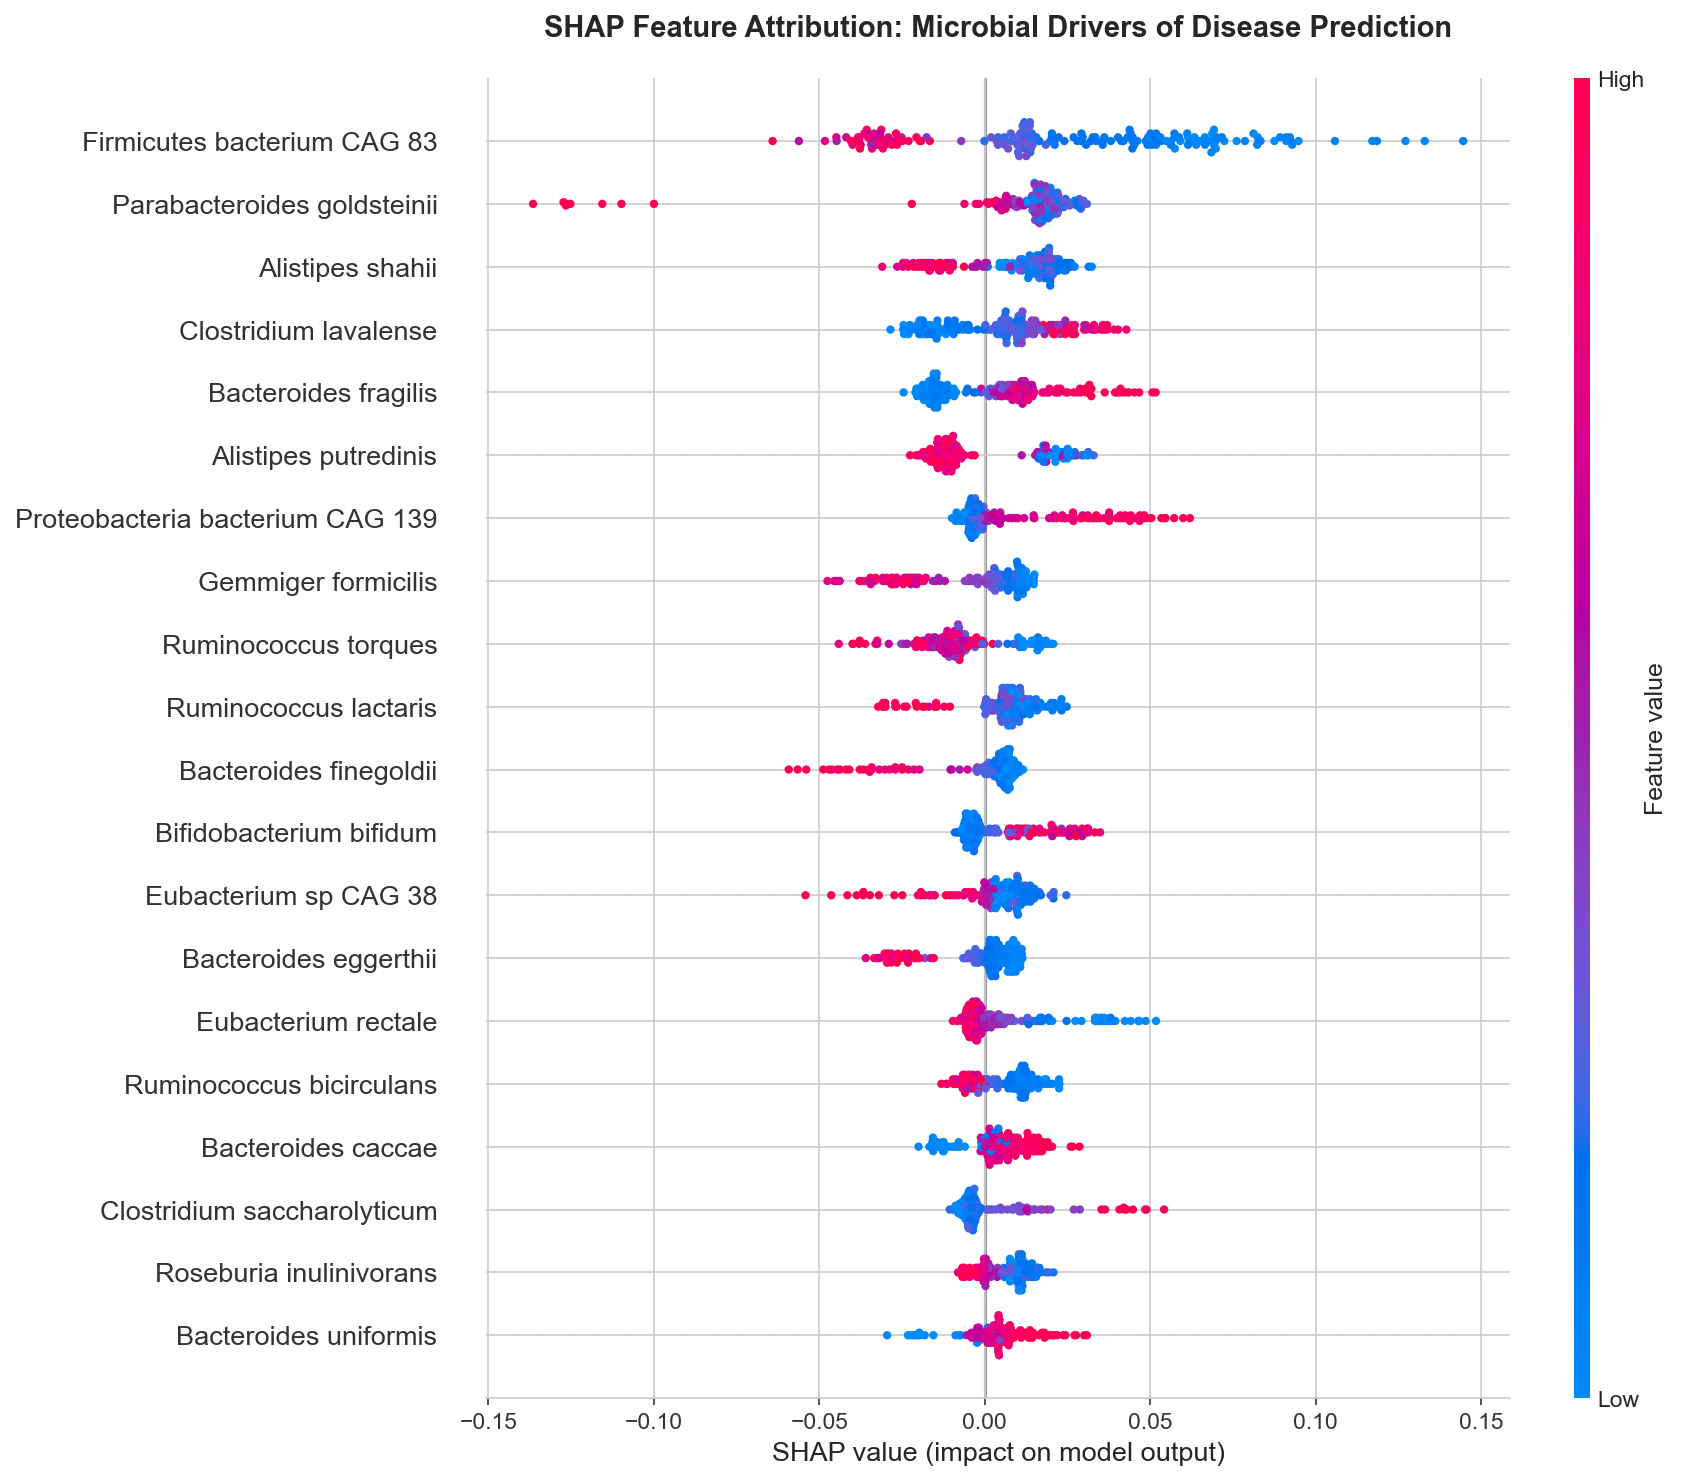


SHAP values decompose each prediction into per-feature contributions.
Features ranked by mean |SHAP| value. Red = high CLR abundance, blue = low.
Positive SHAP pushes toward Crohn's Disease; negative toward Healthy.


In [ ]:
# Figure 18: SHAP Beeswarm Summary Plot
from IPython.display import Image, display

# Recreate SHAP data if not in memory
if 'X_shap' not in dir():
    shap_sample_size = min(500, len(X_test))
    X_shap = X_test.sample(n=shap_sample_size, random_state=SEED)
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_shap)
    shap_vals_cd = shap_values[1] if isinstance(shap_values, list) else shap_values
    print(f"Computed SHAP values for {shap_sample_size} samples.")

# Handle multi-output format
if shap_vals_cd.ndim == 3:
    beeswarm_vals = shap_vals_cd[:, :, 1]  # CD class
else:
    beeswarm_vals = shap_vals_cd

plt.figure(figsize=(12, 10))
shap.summary_plot(beeswarm_vals, X_shap, max_display=20, show=False, plot_size=(12, 10))
plt.title("SHAP Feature Attribution: Microbial Drivers of Disease Prediction",
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.close()

display(Image(filename='shap_beeswarm.png'))
print("\nSHAP values decompose each prediction into per-feature contributions.")
print("Features ranked by mean |SHAP| value. Red = high CLR abundance, blue = low.")
print("Positive SHAP pushes toward Crohn's Disease; negative toward Healthy.")

Generating SHAP waterfall plot...
  Predictions: 11 Healthy, 168 CD
  Using sample at position 0, base_val: 0.5007


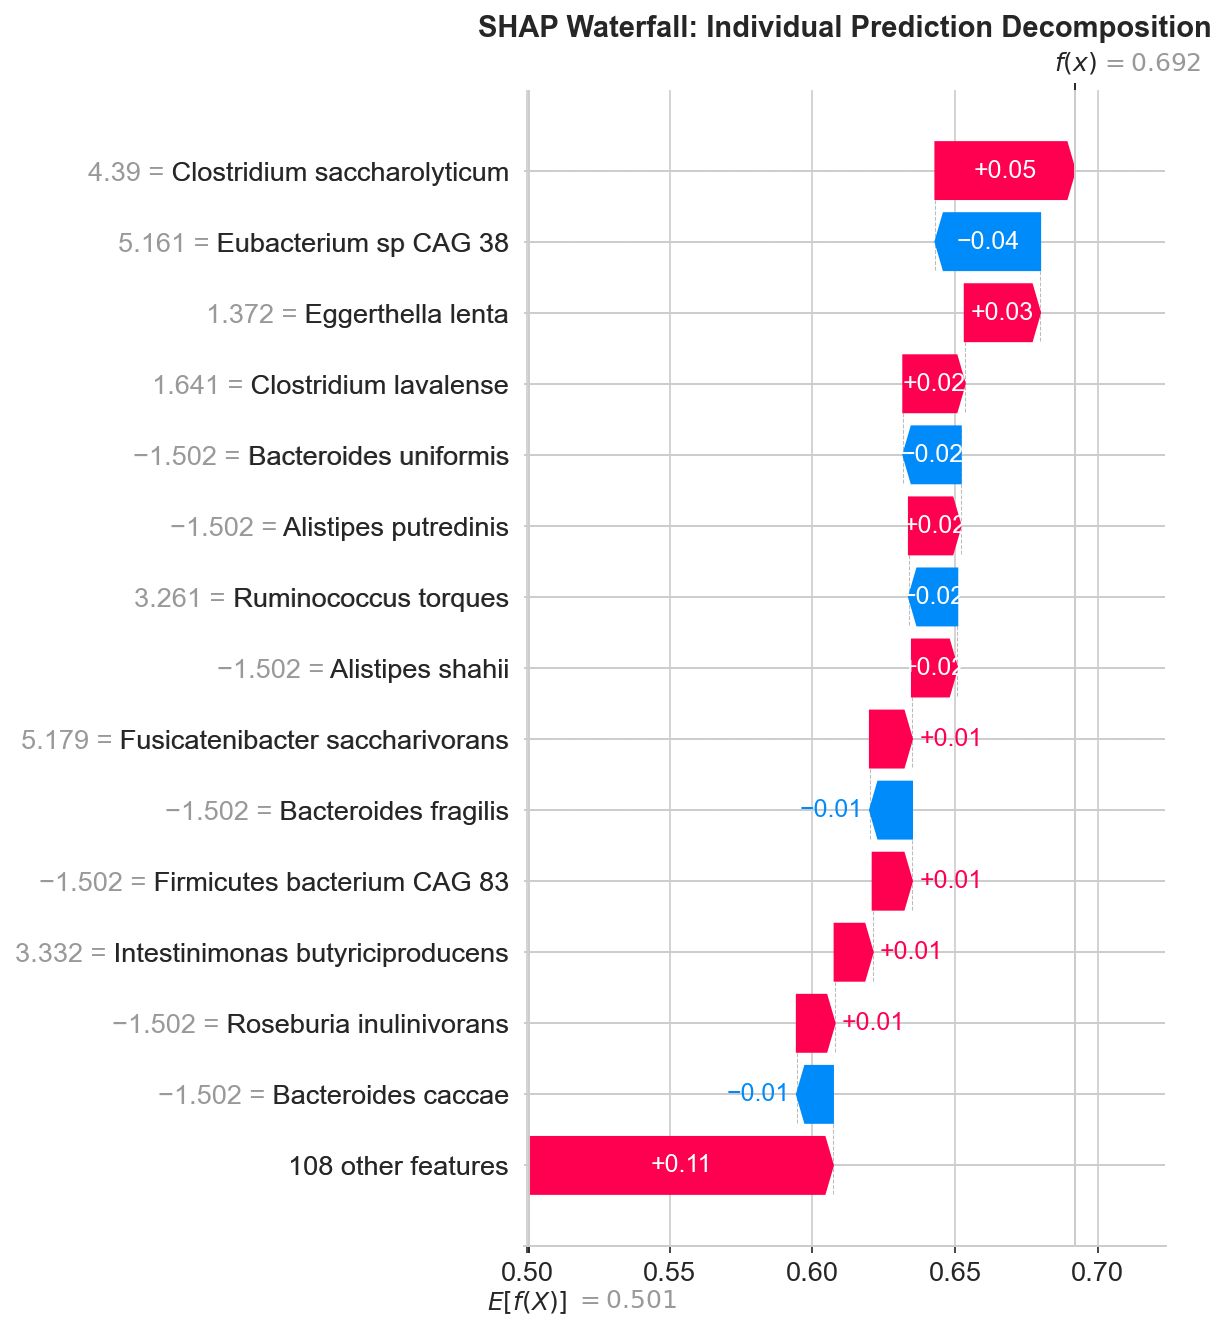

SHAP waterfall plot rendered.


In [ ]:
# Figure 19: SHAP Waterfall for an example Crohn's patient
from IPython.display import Image, display

# Recreate X_shap if not in memory (e.g., after kernel restart)
if 'X_shap' not in dir():
    shap_sample_size = min(500, len(X_test))
    X_shap = X_test.sample(n=shap_sample_size, random_state=SEED)
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_shap)
    shap_vals_cd = shap_values[1] if isinstance(shap_values, list) else shap_values
    print(f"Recomputed SHAP values for {shap_sample_size} samples.")

print("Generating SHAP waterfall plot...")
y_shap_pred = rf_model.predict(X_shap)
print(f"  Predictions: {(y_shap_pred==0).sum()} Healthy, {(y_shap_pred==1).sum()} CD")

cd_pos = 0
for i in range(len(y_shap_pred)):
    if y_shap_pred[i] == 1:
        cd_pos = i
        break

if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_val = float(explainer.expected_value[1])
else:
    base_val = float(explainer.expected_value)

if shap_vals_cd.ndim == 3:
    waterfall_vals = shap_vals_cd[cd_pos, :, 1]
else:
    waterfall_vals = shap_vals_cd[cd_pos]

print(f"  Using sample at position {cd_pos}, base_val: {base_val:.4f}")

explanation = shap.Explanation(
    values=waterfall_vals,
    base_values=base_val,
    data=X_shap.iloc[cd_pos].values,
    feature_names=X_shap.columns.tolist()
)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
shap.waterfall_plot(explanation, max_display=15, show=False)
plt.title("SHAP Waterfall: Individual Prediction Decomposition",
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.close()

display(Image(filename='shap_waterfall.png'))
print("SHAP waterfall plot rendered.")

## Section 10. Longitudinal Microbiome Trajectories: Temporal Dynamics in 4D Space

The longitudinal design of the HMP2 cohort enables characterization of temporal microbiome dynamics at the individual level. We visualize how patients' microbiomes evolve through three-dimensional compositional space over time, with marker properties encoding temporal and clinical metadata. Healthy individuals are hypothesized to maintain stable, low-variance trajectories reflecting a resilient core microbiome, while IBD patients are expected to exhibit erratic, high-variance trajectories corresponding to disease flares and dysbiosis episodes.

In [ ]:
# ---------------------------------------------------------------------------
# Select representative patients with sufficient longitudinal depth
# ---------------------------------------------------------------------------
timepoints_per_patient = metadata_df.groupby('Participant ID').size()
patients_longitudinal = timepoints_per_patient[timepoints_per_patient >= 5].index

n_traj = 4
healthy_traj = metadata_df[
    (metadata_df['diagnosis'] == 'Healthy') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
]['Participant ID'].unique()[:n_traj]

crohns_traj = metadata_df[
    (metadata_df['diagnosis'] == 'Crohns Disease') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
]['Participant ID'].unique()[:n_traj]

uc_traj = metadata_df[
    (metadata_df['diagnosis'] == 'Ulcerative Colitis') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
]['Participant ID'].unique()[:min(2, len(metadata_df[metadata_df['diagnosis']=='Ulcerative Colitis']['Participant ID'].unique()))]

selected_traj = list(healthy_traj) + list(crohns_traj) + list(uc_traj)

traj_data = metadata_df[metadata_df['Participant ID'].isin(selected_traj)].copy()
traj_data = traj_data.sort_values(['Participant ID', 'week_num'])

print(f"Trajectory analysis participants:")
print(f"  Healthy: {list(healthy_traj)}")
print(f"  Crohns:  {list(crohns_traj)}")
print(f"  UC:      {list(uc_traj)}")
print(f"  Total trajectory samples: {len(traj_data)}")

Trajectory analysis participants:
  Healthy: ['C3022', 'H4008', 'H4009', 'H4013']
  Crohns:  ['C3001', 'C3002', 'C3008', 'C3009']
  UC:      ['C3003', 'C3004']
  Total trajectory samples: 132


In [ ]:
# ---------------------------------------------------------------------------
# Figure 20A: Animated Longitudinal Trajectories (3D with play button)
# ---------------------------------------------------------------------------
timepoints_per_patient = metadata_df.groupby('Participant ID').size()
patients_longitudinal = timepoints_per_patient[timepoints_per_patient >= 8].index

n_show = 3
healthy_traj = metadata_df[
    (metadata_df['diagnosis'] == 'Healthy') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
].groupby('Participant ID').size().nlargest(n_show).index.tolist()

crohns_traj = metadata_df[
    (metadata_df['diagnosis'] == 'Crohns Disease') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
].groupby('Participant ID').size().nlargest(n_show).index.tolist()

uc_candidates = metadata_df[
    (metadata_df['diagnosis'] == 'Ulcerative Colitis') &
    (metadata_df['Participant ID'].isin(patients_longitudinal))
]['Participant ID'].unique()
uc_traj = list(uc_candidates[:2])

selected_traj = healthy_traj + crohns_traj + uc_traj
traj_data = metadata_df[metadata_df['Participant ID'].isin(selected_traj)].copy()
traj_data = traj_data.sort_values(['Participant ID', 'week_num'])

# Assign colors
pid_colors = {}
palette_h = ['#1B9E77', '#2DC4A0', '#6EDBBE']
palette_c = ['#D95F02', '#F4813E', '#FF9F6B']
palette_u = ['#7570B3', '#A09BDB']
for i, pid in enumerate(healthy_traj):
    pid_colors[pid] = palette_h[i % len(palette_h)]
for i, pid in enumerate(crohns_traj):
    pid_colors[pid] = palette_c[i % len(palette_c)]
for i, pid in enumerate(uc_traj):
    pid_colors[pid] = palette_u[i % len(palette_u)]

# Normalize week numbers into sequential steps
all_weeks = sorted(traj_data['week_num'].dropna().unique())
n_frames = min(len(all_weeks), 30)  # cap at 30 frames
week_bins = np.linspace(all_weeks[0], all_weeks[-1], n_frames + 1)

# Build frames
frames = []
for frame_idx in range(1, n_frames + 1):
    week_cutoff = week_bins[frame_idx]
    frame_traces = []

    for pid in selected_traj:
        psub = traj_data[(traj_data['Participant ID'] == pid) &
                         (traj_data['week_num'] <= week_cutoff)].sort_values('week_num')
        if len(psub) == 0:
            continue
        diag = psub['diagnosis'].iloc[0]
        color = pid_colors[pid]
        short = {'Healthy': 'H', 'Crohns Disease': 'CD', 'Ulcerative Colitis': 'UC'}[diag]

        # Trail line
        frame_traces.append(go.Scatter3d(
            x=psub['PC1'], y=psub['PC2'], z=psub['PC3'],
            mode='lines', line=dict(color=color, width=5), opacity=0.5,
            name=f'{pid} ({short})', showlegend=False, hoverinfo='skip'
        ))
        # Current position (glowing head)
        frame_traces.append(go.Scatter3d(
            x=[psub['PC1'].iloc[-1]], y=[psub['PC2'].iloc[-1]], z=[psub['PC3'].iloc[-1]],
            mode='markers',
            marker=dict(size=10, color=color, line=dict(width=3, color='white'),
                        opacity=1.0),
            name=f'{pid} ({short})', showlegend=False,
            hovertemplate=f'<b>{pid}</b> ({diag})<br>Week {psub["week_num"].iloc[-1]:.0f}<extra></extra>'
        ))

    frames.append(go.Frame(data=frame_traces, name=f'Week {week_cutoff:.0f}'))

# Initial state (frame 0)
init_traces = frames[0].data if frames else []

fig_anim = go.Figure(data=list(init_traces), frames=frames)

# Slider and buttons
fig_anim.update_layout(
    title=dict(
        text="Animated Longitudinal Trajectories: Microbiome Evolution Over Time<br>"
             "<sub>Press play to watch patients traverse compositional space | Green=Healthy, Orange=CD, Purple=UC</sub>",
        font=dict(size=15, color='#2C3E50')),
    scene=dict(
        xaxis_title=f'PC1 ({var_explained[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({var_explained[1]*100:.1f}%)',
        zaxis_title=f'PC3 ({var_explained[2]*100:.1f}%)',
        camera=dict(eye=dict(x=1.8, y=1.8, z=1.2)),
        xaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white",
                   range=[metadata_df['PC1'].min()-2, metadata_df['PC1'].max()+2]),
        yaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white",
                   range=[metadata_df['PC2'].min()-2, metadata_df['PC2'].max()+2]),
        zaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white",
                   range=[metadata_df['PC3'].min()-2, metadata_df['PC3'].max()+2])
    ),
    template='plotly_white', width=1100, height=850,
    updatemenus=[dict(
        type='buttons', showactive=False,
        x=0.05, y=0.02, xanchor='left', yanchor='bottom',
        buttons=[
            dict(label='Play', method='animate',
                 args=[None, dict(frame=dict(duration=400, redraw=True),
                                  fromcurrent=True, transition=dict(duration=200))]),
            dict(label='Pause', method='animate',
                 args=[[None], dict(frame=dict(duration=0, redraw=True),
                                    mode='immediate', transition=dict(duration=0))])
        ]
    )],
    sliders=[dict(
        active=0, x=0.05, len=0.9, xanchor='left',
        currentvalue=dict(prefix='Week: ', font=dict(size=14)),
        transition=dict(duration=200),
        steps=[dict(args=[[f.name], dict(frame=dict(duration=400, redraw=True),
                                          mode='immediate', transition=dict(duration=200))],
                    method='animate', label=f.name.replace('Week ', ''))
               for f in frames]
    )]
)

fig_anim.show(renderer='notebook_connected')

print("\nPress the Play button to animate patient trajectories through compositional space.")
print("Green trails = Healthy (stable, compact), Orange = Crohn's (erratic, wide-ranging).")


Press the Play button to animate patient trajectories through compositional space.
Green trails = Healthy (stable, compact), Orange = Crohn's (erratic, wide-ranging).


In [ ]:
# ---------------------------------------------------------------------------
# Figure 20B: Trajectories on Density Landscape
# ---------------------------------------------------------------------------
from scipy.stats import gaussian_kde

fig_surf_traj = go.Figure()

# --- 1. Density surfaces for each group ---
pc1_range = np.linspace(metadata_df['PC1'].min()-2, metadata_df['PC1'].max()+2, 50)
pc2_range = np.linspace(metadata_df['PC2'].min()-2, metadata_df['PC2'].max()+2, 50)
PC1g, PC2g = np.meshgrid(pc1_range, pc2_range)
positions = np.vstack([PC1g.ravel(), PC2g.ravel()])

surface_colors = {
    'Healthy': [[0, 'rgba(27,158,119,0)'], [1, 'rgba(27,158,119,0.5)']],
    'Crohns Disease': [[0, 'rgba(217,95,2,0)'], [1, 'rgba(217,95,2,0.5)']],
    'Ulcerative Colitis': [[0, 'rgba(117,112,179,0)'], [1, 'rgba(117,112,179,0.5)']]
}

for diag, cscale in surface_colors.items():
    sub = metadata_df[metadata_df['diagnosis'] == diag]
    if len(sub) < 15:
        continue
    try:
        kde = gaussian_kde(np.vstack([sub['PC1'].values, sub['PC2'].values]), bw_method=0.4)
        Z = kde(positions).reshape(PC1g.shape)
        Z = Z / Z.max() * 8  # scale height for visibility

        fig_surf_traj.add_trace(go.Surface(
            x=PC1g, y=PC2g, z=Z,
            name=f'{diag} density', showscale=False,
            opacity=0.35, colorscale=cscale,
            hovertemplate=f'{diag}<br>Density: %{{z:.2f}}<extra></extra>'
        ))
    except Exception:
        pass

# --- 2. Trajectory lines on top ---
palette_h = ['#0D7358', '#1B9E77', '#2DC4A0']
palette_c = ['#A84400', '#D95F02', '#F4813E']
palette_u = ['#5B56A0', '#7570B3']

color_iters = {
    'Healthy': iter(palette_h),
    'Crohns Disease': iter(palette_c),
    'Ulcerative Colitis': iter(palette_u)
}

for pid in selected_traj:
    psub = traj_data[traj_data['Participant ID'] == pid].sort_values('week_num')
    if len(psub) < 2:
        continue
    diag = psub['diagnosis'].iloc[0]
    color = next(color_iters.get(diag, iter(['#888'])), '#888888')
    short = {'Healthy': 'H', 'Crohns Disease': 'CD', 'Ulcerative Colitis': 'UC'}[diag]

    # Elevate trajectories above surfaces
    z_offset = 10

    fig_surf_traj.add_trace(go.Scatter3d(
        x=psub['PC1'], y=psub['PC2'], z=psub['PC3'] + z_offset,
        mode='lines+markers',
        name=f'{pid} ({short})',
        line=dict(color=color, width=6),
        marker=dict(size=4, color=color, line=dict(width=1, color='white')),
        opacity=0.85,
        hovertemplate=f'<b>{pid}</b> ({diag})<br>'
                      'Week: %{text:.0f}<extra></extra>',
        text=psub['week_num']
    ))

    # Start diamond
    fig_surf_traj.add_trace(go.Scatter3d(
        x=[psub['PC1'].iloc[0]], y=[psub['PC2'].iloc[0]],
        z=[psub['PC3'].iloc[0] + z_offset],
        mode='markers', showlegend=False,
        marker=dict(size=9, color=color, symbol='diamond',
                    line=dict(width=2, color='white'))
    ))

    # End circle
    fig_surf_traj.add_trace(go.Scatter3d(
        x=[psub['PC1'].iloc[-1]], y=[psub['PC2'].iloc[-1]],
        z=[psub['PC3'].iloc[-1] + z_offset],
        mode='markers', showlegend=False,
        marker=dict(size=12, color=color, symbol='circle',
                    line=dict(width=3, color='white'))
    ))

fig_surf_traj.update_layout(
    title=dict(
        text="Microbiome Trajectories over Group Density Landscapes<br>"
             "<sub>Surfaces = group probability density | Lines = individual longitudinal paths</sub>",
        font=dict(size=15, color='#2C3E50')),
    scene=dict(
        xaxis_title=f'PC1 ({var_explained[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({var_explained[1]*100:.1f}%)',
        zaxis_title='Compositional Axis',
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.8)),
        xaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white"),
        yaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white"),
        zaxis=dict(backgroundcolor="rgb(240,240,245)", gridcolor="white")
    ),
    template='plotly_white', width=1100, height=900,
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.9)",
                bordercolor="#CCC", borderwidth=1, font=dict(size=10))
)

fig_surf_traj.show(renderer='notebook_connected')

print("\nTrajectories travel across the probability landscape of each diagnosis group.")
print("Healthy patients follow paths confined to the green density peak.")
print("CD patients traverse widely, often passing through low-density regions.")


Trajectories travel across the probability landscape of each diagnosis group.
Healthy patients follow paths confined to the green density peak.
CD patients traverse widely, often passing through low-density regions.


In [ ]:
# ---------------------------------------------------------------------------
# Figure 21: Dysbiosis Time Series
# ---------------------------------------------------------------------------
fig_ts = go.Figure()

# --- 1. Shaded bands showing group ranges over time ---
for diag, color, fill_color in [
    ('Healthy', '#1B9E77', 'rgba(27,158,119,0.12)'),
    ('Crohns Disease', '#D95F02', 'rgba(217,95,2,0.12)'),
    ('Ulcerative Colitis', '#7570B3', 'rgba(117,112,179,0.12)')
]:
    grp = metadata_df[metadata_df['diagnosis'] == diag].dropna(subset=['week_num', 'dysbiosis_score'])
    if len(grp) < 10:
        continue
    
    # Bin into weekly windows and compute stats
    grp['week_bin'] = (grp['week_num'] // 2) * 2  # 2-week bins
    stats = grp.groupby('week_bin')['dysbiosis_score'].agg(['mean', 'std', 'count'])
    stats = stats[stats['count'] >= 3].sort_index()
    
    if len(stats) < 3:
        continue
    
    upper = stats['mean'] + stats['std']
    lower = stats['mean'] - stats['std']
    
    # Confidence band
    fig_ts.add_trace(go.Scatter(
        x=list(stats.index) + list(stats.index[::-1]),
        y=list(upper) + list(lower[::-1]),
        fill='toself', fillcolor=fill_color,
        line=dict(color='rgba(0,0,0,0)'),
        name=f'{diag} range', showlegend=False, hoverinfo='skip'
    ))
    
    # Group mean trend
    fig_ts.add_trace(go.Scatter(
        x=stats.index, y=stats['mean'],
        mode='lines', name=f'{diag} (mean)',
        line=dict(color=color, width=4, dash='dot'),
        opacity=0.6
    ))

# --- 2. Individual patient trajectories ---
palette_h = ['#1B9E77', '#2DC4A0', '#6EDBBE']
palette_c = ['#D95F02', '#F4813E', '#FF9F6B']
palette_u = ['#7570B3', '#A09BDB']

color_iters = {
    'Healthy': iter(palette_h),
    'Crohns Disease': iter(palette_c),
    'Ulcerative Colitis': iter(palette_u)
}

for pid in selected_traj:
    psub = traj_data[traj_data['Participant ID'] == pid].sort_values('week_num')
    psub = psub.dropna(subset=['dysbiosis_score'])
    if len(psub) < 2:
        continue
    diag = psub['diagnosis'].iloc[0]
    color = next(color_iters.get(diag, iter(['#888'])), '#888888')
    short = {'Healthy': 'H', 'Crohns Disease': 'CD', 'Ulcerative Colitis': 'UC'}[diag]

    fig_ts.add_trace(go.Scatter(
        x=psub['week_num'], y=psub['dysbiosis_score'],
        mode='lines+markers',
        name=f'{pid} ({short})',
        line=dict(color=color, width=2.5, shape='spline'),  # smooth curves
        marker=dict(size=6, color=color, line=dict(width=1.5, color='white')),
        hovertemplate=(
            f'<b>{pid}</b> ({diag})<br>'
            'Week: %{x:.0f}<br>'
            'Dysbiosis: %{y:.3f}<br>'
            '<extra></extra>'
        )
    ))

# --- 3. Reference lines and zones ---
fig_ts.add_hline(y=0, line_dash="dash", line_color="#2C3E50", line_width=2,
                 annotation_text="Balanced", annotation_position="top left",
                 annotation_font=dict(size=11, color="#2C3E50"))

# Dysbiotic zone shading
fig_ts.add_hrect(y0=0, y1=5, fillcolor="rgba(231,76,60,0.06)",
                 line_width=0, annotation_text="Dysbiotic",
                 annotation_position="top right",
                 annotation_font=dict(size=10, color="#E74C3C"))
fig_ts.add_hrect(y0=-5, y1=0, fillcolor="rgba(46,204,113,0.06)",
                 line_width=0, annotation_text="Symbiont-dominated",
                 annotation_position="bottom right",
                 annotation_font=dict(size=10, color="#27AE60"))

fig_ts.update_layout(
    title=dict(
        text="Temporal Dynamics of Dysbiosis: Longitudinal Pathobiont-Symbiont Balance<br>"
             "<sub>Individual trajectories with group trend bands (mean +/- 1 SD)</sub>",
        font=dict(size=15, color='#2C3E50')),
    xaxis_title=dict(text="Weeks from Baseline", font=dict(size=13)),
    yaxis_title=dict(text="Dysbiosis Score (Log10[Pathobionts/Symbionts])", font=dict(size=12)),
    template='plotly_white', width=1100, height=650,
    legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.9)",
                bordercolor="#DDD", borderwidth=1, font=dict(size=10)),
    yaxis=dict(zeroline=False)
)

fig_ts.show(renderer='notebook_connected')

print("\nShaded bands show group-level trends (mean +/- 1 SD).")
print("Individual lines show patient-specific dynamics.")
print("The red-shaded zone (above 0) indicates pathobiont dominance.")


Shaded bands show group-level trends (mean +/- 1 SD).
Individual lines show patient-specific dynamics.
The red-shaded zone (above 0) indicates pathobiont dominance.


In [ ]:
# ---------------------------------------------------------------------------
# Figure 22: Trajectory Volatility Analysis
# ---------------------------------------------------------------------------
volatility_data = []
for pid in patients_longitudinal:
    psub = metadata_df[metadata_df['Participant ID'] == pid]
    if len(psub) < 3:
        continue
    diag = psub['diagnosis'].iloc[0]
    pc_std = np.sqrt(psub['PC1'].std()**2 + psub['PC2'].std()**2 + psub['PC3'].std()**2)
    dys_std = psub['dysbiosis_score'].std()
    mean_shannon = psub['shannon'].mean()
    volatility_data.append({
        'participant': pid, 'diagnosis': diag,
        'trajectory_volatility': pc_std,
        'dysbiosis_volatility': dys_std,
        'mean_shannon': mean_shannon,
        'n_timepoints': len(psub)
    })

vol_df = pd.DataFrame(volatility_data)

fig_vol = go.Figure()
for diag, color in PALETTE_DIAGNOSIS.items():
    sub = vol_df[vol_df['diagnosis'] == diag]
    if len(sub) == 0:
        continue
    fig_vol.add_trace(go.Scatter3d(
        x=sub['trajectory_volatility'],
        y=sub['dysbiosis_volatility'],
        z=sub['mean_shannon'],
        mode='markers', name=diag,
        marker=dict(
            size=sub['n_timepoints'], color=color,
            opacity=0.75, line=dict(width=0.5, color='white'),
            sizemin=4, sizeref=1
        ),
        text=sub['participant'],
        hovertemplate=(
            '<b>%{text}</b><br>'
            f'{diag}<br>'
            'Trajectory Volatility: %{x:.3f}<br>'
            'Dysbiosis Volatility: %{y:.3f}<br>'
            'Mean Shannon: %{z:.3f}<br>'
            '<extra></extra>'
        )
    ))

fig_vol.update_layout(
    title=dict(
        text="Participant-Level Stability: Trajectory and Dysbiosis Volatility<br>"
             "<sub>Each point = one participant | Marker size = number of timepoints</sub>",
        font=dict(size=16)),
    scene=dict(
        xaxis_title='Trajectory Volatility (SD in PC space)',
        yaxis_title='Dysbiosis Volatility (SD of score)',
        zaxis_title='Mean Shannon Diversity',
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.2))
    ),
    template='plotly_white', width=1050, height=800,
    legend=dict(x=0.02, y=0.98)
)

fig_vol.show(renderer='notebook_connected')

print("\nHealthy participants cluster in the low-volatility, high-diversity region,")
print("while Crohn's Disease participants exhibit elevated volatility on both axes,")
print("confirming that temporal instability is a hallmark of the dysbiotic gut.")



Healthy participants cluster in the low-volatility, high-diversity region,
while Crohn's Disease participants exhibit elevated volatility on both axes,
confirming that temporal instability is a hallmark of the dysbiotic gut.


## Section 11. Microbial Co-Occurrence Network: Ecological Interaction Architecture

Microbial communities are structured by interspecies interactions including mutualism, competition, and cross-feeding. We reconstruct a co-occurrence network from Spearman correlations on CLR-transformed data, which are appropriate for compositional data (unlike correlations on raw relative abundances, which suffer from spurious negative correlations due to the compositional constraint). Network topology identifies candidate hub species, ecological modules, and patterns of synergistic versus antagonistic interactions.


In [ ]:
# ---------------------------------------------------------------------------
# CLR-based network construction with FDR-controlled edges
# ---------------------------------------------------------------------------
species_var = clr_data.var(axis=0).sort_values(ascending=False)
top_net_species = list(species_var.head(50).index)
net_data = clr_data[top_net_species].copy()

nonzero_var = net_data.var() > 0
net_data = net_data.loc[:, nonzero_var]
top_net_species = list(net_data.columns)
n_net = len(top_net_species)
print(f"Species with nonzero CLR variance: {n_net}")

rho_list, pval_list, pair_list = [], [], []
for i in range(n_net):
    for j in range(i + 1, n_net):
        r, p = spearmanr(net_data.iloc[:, i], net_data.iloc[:, j])
        rho_list.append(r)
        pval_list.append(p)
        pair_list.append((top_net_species[i], top_net_species[j]))

rho_arr = np.asarray(rho_list)
pval_arr = np.asarray(pval_list)
pval_adj = multipletests(pval_arr, method='fdr_bh')[1]

rho_threshold = 0.30
edges = [
    {
        'source': pair_list[k][0],
        'target': pair_list[k][1],
        'weight': rho_arr[k],
        'pval_adj': pval_adj[k]
    }
    for k in range(len(pair_list))
    if np.isfinite(rho_arr[k])
    and abs(rho_arr[k]) > rho_threshold
    and pval_adj[k] < 0.05
]

print(f"FDR < 0.05 and |rho| > {rho_threshold}: {len(edges)} edges")
if not edges:
    print("No edges passed the prespecified thresholds; no fallback noise-network is created.")

G = nx.Graph()
for e in edges:
    G.add_edge(e['source'], e['target'], weight=e['weight'], padj=e['pval_adj'])

degree_cent = nx.degree_centrality(G) if G.number_of_nodes() else {}
betw_cent = nx.betweenness_centrality(G) if G.number_of_nodes() else {}
sorted_hubs = sorted(degree_cent.items(), key=lambda x: x[1], reverse=True)[:10]

print(f"Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
if sorted_hubs:
    print("\nTop candidate hubs (descriptive, not causal):")
    for sp, dc in sorted_hubs:
        print(f"  {sp}: degree={dc:.3f}, betweenness={betw_cent.get(sp, 0):.3f}")


Species with nonzero CLR variance: 50
FDR < 0.05 and |rho| > 0.3: 56 edges
Network: 38 nodes, 56 edges

Top candidate hubs (descriptive, not causal):
  Clostridium symbiosum: degree=0.216, betweenness=0.237
  Alistipes shahii: degree=0.189, betweenness=0.074
  Clostridium bolteae: degree=0.189, betweenness=0.198
  Flavonifractor plautii: degree=0.189, betweenness=0.066
  Ruminococcus gnavus: degree=0.162, betweenness=0.126
  Alistipes putredinis: degree=0.135, betweenness=0.018
  Prevotella copri: degree=0.135, betweenness=0.116
  Bacteroides massiliensis: degree=0.135, betweenness=0.089
  Bacteroides eggerthii: degree=0.135, betweenness=0.187
  Alistipes finegoldii: degree=0.108, betweenness=0.010


In [ ]:
# ---------------------------------------------------------------------------
# Figure 23: 3D Co-Occurrence Network
# ---------------------------------------------------------------------------
if G.number_of_nodes() > 0:
    pos_3d = nx.spring_layout(G, dim=3, seed=SEED, iterations=80)

    node_x = [pos_3d[n][0] for n in G.nodes()]
    node_y = [pos_3d[n][1] for n in G.nodes()]
    node_z = [pos_3d[n][2] for n in G.nodes()]

    node_sizes = [degree_cent.get(n, 0) * 80 + 6 for n in G.nodes()]
    node_colors = [bacteria_filtered[n].mean() if n in bacteria_filtered.columns else 0
                   for n in G.nodes()]

    fig_net = go.Figure()

    pos_edges_x, pos_edges_y, pos_edges_z = [], [], []
    neg_edges_x, neg_edges_y, neg_edges_z = [], [], []

    for u, v, d in G.edges(data=True):
        x0, y0, z0 = pos_3d[u]
        x1, y1, z1 = pos_3d[v]
        if d['weight'] > 0:
            pos_edges_x += [x0, x1, None]
            pos_edges_y += [y0, y1, None]
            pos_edges_z += [z0, z1, None]
        else:
            neg_edges_x += [x0, x1, None]
            neg_edges_y += [y0, y1, None]
            neg_edges_z += [z0, z1, None]

    if pos_edges_x:
        fig_net.add_trace(go.Scatter3d(
            x=pos_edges_x, y=pos_edges_y, z=pos_edges_z,
            mode='lines', name='Co-occurrence (+)',
            line=dict(color='#3498DB', width=2), opacity=0.5
        ))
    if neg_edges_x:
        fig_net.add_trace(go.Scatter3d(
            x=neg_edges_x, y=neg_edges_y, z=neg_edges_z,
            mode='lines', name='Co-exclusion (-)',
            line=dict(color='#E74C3C', width=2), opacity=0.5
        ))

    fig_net.add_trace(go.Scatter3d(
        x=node_x, y=node_y, z=node_z,
        mode='markers+text', name='Species',
        marker=dict(
            size=node_sizes, color=node_colors,
            colorscale='Viridis', showscale=True,
            colorbar=dict(title="Mean<br>Abundance", x=1.08),
            line=dict(width=1, color='white')
        ),
        text=[n[:25] for n in G.nodes()],
        textposition='top center', textfont=dict(size=7),
        customdata=[[degree_cent.get(n,0), betw_cent.get(n,0)] for n in G.nodes()],
        hovertemplate=(
            '<b>%{text}</b><br>'
            'Degree centrality: %{customdata[0]:.3f}<br>'
            'Betweenness: %{customdata[1]:.3f}<br>'
            '<extra></extra>'
        )
    ))

    fig_net.update_layout(
        title=dict(
            text="3D Microbial Co-Occurrence Network: Ecological Interactions<br>"
                 "<sub>Force-directed layout | Node size = degree | Blue = co-occurrence | Red = exclusion</sub>",
            font=dict(size=16)),
        scene=dict(
            xaxis=dict(showbackground=False, showticklabels=False, title=""),
            yaxis=dict(showbackground=False, showticklabels=False, title=""),
            zaxis=dict(showbackground=False, showticklabels=False, title=""),
            camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
        ),
        template='plotly_white', width=1100, height=900,
        legend=dict(x=0.02, y=0.98)
    )

    fig_net.show(renderer='notebook_connected')
else:
    print("Network has no nodes. Skipping 3D visualization.")

## Section 12. Clinical–Microbial Correlation Analysis

Species–clinical associations are calculated using **one mean value per participant** to avoid pseudoreplication from longitudinal visits. Species values are CLR-transformed abundances. Fecal calprotectin, dysbiosis score, and Shannon diversity are averaged within participant for this cohort-level analysis. These associations are exploratory and do not establish causation.


In [ ]:
# ---------------------------------------------------------------------------
# Figure 24: Participant-level clinical correlation heatmap
# ---------------------------------------------------------------------------
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

top_da_species = (
    volcano_df.nlargest(15, 'log2fc')['species'].tolist() +
    volcano_df.nsmallest(15, 'log2fc')['species'].tolist()
)
top_da_species = list(dict.fromkeys(s for s in top_da_species if s in clr_data.columns))
clinical_vars = [v for v in ['fecalcal', 'dysbiosis_score', 'shannon']
                 if v in metadata_df.columns]

participant_species = (
    clr_data[top_da_species]
    .join(metadata_df[['Participant ID']])
    .groupby('Participant ID')
    .mean()
)
participant_clin = (
    metadata_df[['Participant ID'] + clinical_vars]
    .groupby('Participant ID')
    .mean()
)
combined = participant_clin.join(participant_species, how='inner')
corr_full = combined.corr(method='spearman', min_periods=5)
corr_clin = corr_full.copy()

try:
    distance = 1 - np.abs(corr_full.fillna(0).values)
    np.fill_diagonal(distance, 0)
    link = linkage(squareform(distance, checks=False), method='average')
    order = leaves_list(link)
    ordered_vars = [corr_full.columns[i] for i in order]
    corr_ordered = corr_full.loc[ordered_vars, ordered_vars]
except Exception:
    corr_ordered = corr_full
    ordered_vars = list(corr_full.columns)

n = len(ordered_vars)
corr_tri = corr_ordered.values.astype(float).copy()
corr_tri[np.triu_indices(n, k=1)] = np.nan

fig_heat = go.Figure(data=go.Heatmap(
    z=corr_tri[::-1],
    x=ordered_vars,
    y=ordered_vars[::-1],
    colorscale='RdBu_r',
    zmin=-1, zmax=1,
    xgap=1.5, ygap=1.5,
    hovertemplate='<b>%{y}</b><br>vs <b>%{x}</b><br>'
                  'Spearman rho: %{z:.3f}<extra></extra>',
    colorbar=dict(title='Spearman<br>rho', thickness=18, len=0.75)
))
fig_heat.update_layout(
    title=dict(
        text="Participant-Level Species–Clinical Correlations<br>"
             "<sub>One mean per participant; CLR species abundances</sub>",
        font=dict(size=16)),
    width=1100, height=1000,
    xaxis=dict(tickangle=-45, tickfont=dict(size=8)),
    yaxis=dict(tickfont=dict(size=8)),
    template='plotly_white',
    margin=dict(l=220, r=100, t=100, b=220)
)
fig_heat.show(renderer='notebook_connected')


In [ ]:
# ---------------------------------------------------------------------------
# Figure 25: Participant-level species vs fecal calprotectin
# ---------------------------------------------------------------------------
if 'fecalcal' in corr_clin.columns:
    fc_corr = corr_clin['fecalcal'].drop(
        ['fecalcal', 'dysbiosis_score', 'shannon'], errors='ignore'
    ).dropna()

    top_pos_sp = fc_corr.nlargest(1).index[0] if len(fc_corr) else None
    top_neg_sp = fc_corr.nsmallest(1).index[0] if len(fc_corr) else None

    participant_plot = (
        participant_clin[['fecalcal']]
        .join(participant_species, how='inner')
        .join(
            metadata_df[['Participant ID', 'diagnosis']]
            .drop_duplicates('Participant ID')
            .set_index('Participant ID')
        )
    ).dropna(subset=['fecalcal'])

    if top_pos_sp and top_neg_sp:
        fig_scatter_cl = make_subplots(
            rows=1, cols=2,
            subplot_titles=(
                f'{top_pos_sp} (largest positive rho)',
                f'{top_neg_sp} (largest negative rho)'
            )
        )

        for col_idx, species in enumerate([top_pos_sp, top_neg_sp], 1):
            for diag, color in PALETTE_DIAGNOSIS.items():
                sub = participant_plot[participant_plot['diagnosis'] == diag].dropna(
                    subset=[species]
                )
                if sub.empty:
                    continue
                fig_scatter_cl.add_trace(go.Scatter(
                    x=sub[species],
                    y=np.log10(sub['fecalcal'].clip(lower=1)),
                    mode='markers',
                    name=diag if col_idx == 1 else None,
                    marker=dict(color=color, size=7, opacity=0.7),
                    showlegend=(col_idx == 1),
                    hovertemplate=(
                        f'<b>{diag}</b><br>{species} CLR: %{{x:.2f}}<br>'
                        'Log10(mean fecalcal): %{y:.2f}<extra></extra>'
                    )
                ), row=1, col=col_idx)

        fig_scatter_cl.update_layout(
            title=dict(
                text="Participant-Level Clinical Associations<br>"
                     "<sub>Mean CLR abundance vs. mean fecal calprotectin</sub>",
                font=dict(size=16)),
            template='plotly_white', width=1100, height=550
        )
        fig_scatter_cl.update_xaxes(title_text="Mean CLR abundance")
        fig_scatter_cl.update_yaxes(title_text="Log10(mean fecal calprotectin)")
        fig_scatter_cl.show(renderer='notebook_connected')


In [ ]:
# ---------------------------------------------------------------------------
# Figure 26: Exploratory participant-level clinical integration scatter
# ---------------------------------------------------------------------------
candidate_x = 'Faecalibacterium prausnitzii'
candidate_y = 'Escherichia coli'

if candidate_x in participant_species.columns and candidate_y in participant_species.columns:
    plot3_df = (
        participant_species[[candidate_x, candidate_y]]
        .join(participant_clin[['fecalcal']])
        .join(
            metadata_df[['Participant ID', 'diagnosis']]
            .drop_duplicates('Participant ID')
            .set_index('Participant ID')
        )
        .dropna()
    )

    fig_3dclin = go.Figure()
    for diag, color in PALETTE_DIAGNOSIS.items():
        sub = plot3_df[plot3_df['diagnosis'] == diag]
        if sub.empty:
            continue
        fig_3dclin.add_trace(go.Scatter3d(
            x=sub[candidate_x], y=sub[candidate_y],
            z=np.log10(sub['fecalcal'].clip(lower=1)),
            mode='markers', name=diag,
            marker=dict(size=5, color=color, opacity=0.7),
            hovertemplate=(
                f'{candidate_x} CLR: %{{x:.2f}}<br>'
                f'{candidate_y} CLR: %{{y:.2f}}<br>'
                'Log10(mean fecalcal): %{z:.2f}<extra></extra>'
            )
        ))

    fig_3dclin.update_layout(
        title=dict(
            text="Exploratory Participant-Level Clinical Integration<br>"
                 "<sub>No protective or disease association is assumed without statistical support</sub>",
            font=dict(size=16)),
        scene=dict(
            xaxis_title=f'{candidate_x} (mean CLR)',
            yaxis_title=f'{candidate_y} (mean CLR)',
            zaxis_title='Log10(mean fecal calprotectin)'
        ),
        template='plotly_white', width=1050, height=800
    )
    fig_3dclin.show(renderer='notebook_connected')


## Section 13. Integrated Results Summary and Data Export

This section consolidates all quantitative findings from the preceding analyses into a structured summary and exports key results tables for downstream use or publication preparation.

In [ ]:
# ---------------------------------------------------------------------------
# Results export and computed summary
# ---------------------------------------------------------------------------
import os
os.makedirs('results', exist_ok=True)

if 'volcano_df' in locals():
    volcano_df.to_csv('results/differential_abundance_participant_level.csv', index=False)
if 'alpha_test_results' in locals():
    alpha_test_results.to_csv('results/alpha_diversity_participant_tests.csv', index=False)
if 'dysbiosis_correlations' in locals():
    dysbiosis_correlations.to_csv('results/dysbiosis_participant_correlations.csv', index=False)
if 'permanova_result' in locals():
    pd.DataFrame([permanova_result]).to_csv('results/permanova_participant_level.csv', index=False)
if 'cv_summary' in locals():
    pd.DataFrame([
        {'metric': k, 'mean': v[0], 'sd': v[1]} for k, v in cv_summary.items()
    ]).to_csv('results/grouped_cv_performance.csv', index=False)
if 'G' in locals() and G.number_of_nodes() > 0:
    hub_df = pd.DataFrame({
        'species': list(degree_cent),
        'degree_centrality': [degree_cent[s] for s in degree_cent],
        'betweenness_centrality': [betw_cent[s] for s in degree_cent]
    }).sort_values('degree_centrality', ascending=False)
    hub_df.to_csv('results/network_hub_species_clr_fdr.csv', index=False)

print("\n" + "=" * 80)
print("COMPUTED ANALYSIS SUMMARY")
print("=" * 80)
print(f"Deduplicated samples: {len(df_full)}")
print(f"Participants: {metadata_full['Participant ID'].nunique()}")
print(f"Species before/after prevalence filter: "
      f"{bacteria_full.shape[1]}/{bacteria_filtered.shape[1]}")

if 'alpha_test_results' in locals():
    print("\nAlpha-diversity participant-level tests:")
    print(alpha_test_results.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

if 'permanova_result' in locals():
    print(f"\nPERMANOVA: F={permanova_result['pseudo_F']:.3f}, "
          f"R2={permanova_result['R2']:.3f}, p={permanova_result['p']:.4f}")

if 'volcano_df' in locals():
    print(f"\nDifferential species at FDR < 0.05: "
          f"{(volcano_df['padj'] < 0.05).sum()} / {len(volcano_df)}")

if 'cv_summary' in locals():
    print("\nParticipant-grouped CV:")
    for metric, (mean_val, sd_val) in cv_summary.items():
        print(f"  {metric}: {mean_val:.3f} +/- {sd_val:.3f}")
    print(f"  Holdout majority-class accuracy baseline: {baseline_acc:.3f}")

if 'G' in locals():
    print(f"\nCLR/FDR network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

print("=" * 80)



COMPUTED ANALYSIS SUMMARY
Deduplicated samples: 1373
Participants: 116
Species before/after prevalence filter: 566/122

Alpha-diversity participant-level tests:
  metric      H        p    padj
 shannon  3.988   0.1361  0.2722
 simpson  1.289   0.5249  0.6999
richness  12.42 0.002005 0.00802
  pielou 0.5016   0.7782  0.7782

PERMANOVA: F=1.528, R2=0.026, p=0.0100

Differential species at FDR < 0.05: 22 / 122

Participant-grouped CV:
  accuracy: 0.680 +/- 0.055
  precision: 0.692 +/- 0.060
  recall: 0.902 +/- 0.049
  f1: 0.782 +/- 0.051
  roc_auc: 0.658 +/- 0.103
  Holdout majority-class accuracy baseline: 0.592

CLR/FDR network: 38 nodes, 56 edges


## Section 14. Conclusions and Future Directions

### How conclusions should be read

This notebook intentionally avoids fixed claims that are printed regardless of the output. Final interpretation should be based on the computed tables produced above:

1. **Alpha diversity**: use the participant-level Kruskal–Wallis results and FDR-adjusted p-values. Sample-level violin plots are descriptive only.
2. **Beta diversity**: use participant-level PERMANOVA to determine whether diagnosis explains a statistically detectable proportion of Aitchison-space variation. Visual overlap or separation alone is not a test.
3. **Differential abundance**: use participant-level mean CLR values with Benjamini–Hochberg correction. Do not describe a species as enriched, depleted, protective, or harmful unless its corrected result supports that statement.
4. **Clinical correlations**: use participant-level summaries. Correlation is association, not causation.
5. **Machine learning**: report participant-grouped cross-validation alongside the majority-class baseline and the train–test gap. A high training score with substantially lower validation performance indicates overfitting.
6. **Network analysis**: edges are retained only when they pass the prespecified CLR-based correlation and FDR thresholds. Network hubs are candidate associations, not demonstrated ecological keystones.
7. **Longitudinal trajectories**: trajectory figures are exploratory unless paired with an explicit participant-level longitudinal model.

### Limitations that remain

- Relative-abundance data do not measure absolute microbial load.
- Zero replacement influences CLR values in sparse taxa and should be checked with sensitivity analyses.
- Averaging repeated visits produces a valid participant-level comparison but discards temporal information; mixed-effects models are preferable when visit-level change is the scientific target.
- Taxonomic profiles are observational, so disease association does not establish microbial causation.
- The heuristic genus-to-phylum mapping used for the radar chart should be replaced with an authoritative taxonomy table before publication.
- Model performance should be externally validated in a separate cohort before any clinical claim.

### Recommended next analyses

1. Fit mixed-effects models with participant as a random effect for longitudinal abundance, diversity, and fecal-calprotectin associations.
2. Repeat key CLR analyses under alternative zero-replacement strategies.
3. Use a compositional differential-abundance method designed for microbiome data as a sensitivity analysis.
4. Validate predictive models in an independent cohort and calibrate predicted probabilities.
5. Integrate metabolomics and host transcriptomics only after matching samples and preserving participant/timepoint grouping.

---

**Data availability**: HMP2 IBDMDB taxonomic profiles are publicly available through IBDMDB.  
**Notebook provenance**: Adapted from the Kaggle notebook *Human Gut Microbiome Atlas* by Qasim Hu; corrections documented in the inserted change log.

**References**
- Aitchison, J. (1986). *The Statistical Analysis of Compositional Data.*
- Lloyd-Price, J. et al. (2019). Multi-omics of the gut microbial ecosystem in inflammatory bowel diseases. *Nature*, 569, 655–662.
- Lundberg, S. M. and Lee, S. I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.
